# 数据预处理

In [10]:
# 读取附件 1-4 

import pandas as pd
# 正确读取 Excel 文件
df1 = pd.read_excel('附件1.xlsx', sheet_name='Sheet1')
df2 = pd.read_excel('附件2.xlsx', sheet_name='Sheet1')
df3 = pd.read_excel('附件3.xlsx', sheet_name='Sheet1')
df4 = pd.read_excel('附件4.xlsx', sheet_name='Sheet1')

# 显示文件内容
print(df1.head(5))
print(df2.head(5))
print(df3.head(5))
print(df4.head(5))

# 将 df 正确输出为csv 格式，保证没有数据错误或者丢失
df1.to_csv('附件1.csv', index=False)
df2.to_csv('附件2.csv', index=False)
df3.to_csv('附件3.csv', index=False)
df4.to_csv('附件4.csv', index=False)



              单品编码    单品名称        分类编码 分类名称
0  102900005115168    牛首生菜  1011010101  花叶类
1  102900005115199   四川红香椿  1011010101  花叶类
2  102900005115625  本地小毛白菜  1011010101  花叶类
3  102900005115748     白菜苔  1011010101  花叶类
4  102900005115762      苋菜  1011010101  花叶类
        销售日期        扫码销售时间             单品编码  销量(千克)  销售单价(元/千克) 销售类型 是否打折销售
0 2020-07-01  09:15:07.924  102900005117056   0.396         7.6   销售      否
1 2020-07-01  09:17:27.295  102900005115960   0.849         3.2   销售      否
2 2020-07-01  09:17:33.905  102900005117056   0.409         7.6   销售      否
3 2020-07-01  09:19:45.450  102900005115823   0.421        10.0   销售      否
4 2020-07-01  09:20:23.686  102900005115908   0.539         8.0   销售      否
          日期             单品编码  批发价格(元/千克)
0 2020-07-01  102900005115762        3.88
1 2020-07-01  102900005115779        6.72
2 2020-07-01  102900005115786        3.19
3 2020-07-01  102900005115793        9.24
4 2020-07-01  102900005115823        7.03
              单品编码     单品名称 

In [13]:
# 缺失值处理
df1 = df1.dropna(inplace=False)
df2 = df2.dropna(inplace=False)
df3 = df3.dropna(inplace=False)
df4 = df4.dropna(inplace=False)
    
# 显示删除的缺失值
print(df1.isnull().sum())
print(df2.isnull().sum())
print(df3.isnull().sum())
print(df4.isnull().sum())



单品编码    0
单品名称    0
分类编码    0
分类名称    0
dtype: int64
销售日期          0
扫码销售时间        0
单品编码          0
销量(千克)        0
销售单价(元/千克)    0
销售类型          0
是否打折销售        0
dtype: int64
日期            0
单品编码          0
批发价格(元/千克)    0
dtype: int64
单品编码      0
单品名称      0
损耗率(%)    0
dtype: int64


In [27]:
# 将 df1 中的单品编码和分类编码作为一个字典
product_category_dict = df1.set_index('单品编码')['分类名称'].to_dict()

print(product_category_dict)

# 在df2中增加一列“分类名称”
df2['分类名称'] = df2['单品编码'].map(product_category_dict)



{102900005115168: '花叶类', 102900005115199: '花叶类', 102900005115625: '花叶类', 102900005115748: '花叶类', 102900005115762: '花叶类', 102900005115779: '花叶类', 102900005115786: '花叶类', 102900005115793: '花叶类', 102900005115816: '花叶类', 102900005115823: '花叶类', 102900005115854: '花叶类', 102900005115861: '花叶类', 102900005115878: '花叶类', 102900005115885: '花叶类', 102900005115908: '花叶类', 102900005115946: '花叶类', 102900005115960: '花叶类', 102900005115977: '花叶类', 102900005115984: '花叶类', 102900005116639: '花叶类', 102900005116776: '花叶类', 102900005116790: '花叶类', 102900005116806: '花叶类', 102900005118572: '花叶类', 102900005118817: '花叶类', 102900005118831: '花叶类', 102900005119975: '花叶类', 102900005122654: '花叶类', 102900005128748: '花叶类', 102900011000175: '花叶类', 102900011000571: '花叶类', 102900011002414: '花叶类', 102900011006689: '花叶类', 102900011006948: '花叶类', 102900011006955: '花叶类', 102900011007464: '花叶类', 102900011007471: '花叶类', 102900011007495: '花叶类', 102900011008133: '花叶类', 102900011008164: '花叶类', 102900011008485: '花叶类', 102900011008492

In [28]:
# 对 df2 中的销售日期进行季节性分类
def categorize_season(date):
    if date.month in [12, 1, 2]:
        return '冬季'
    elif date.month in [3, 4, 5]:
        return '春季'
    elif date.month in [6, 7, 8]:
        return '夏季'
    else:
        return '秋季'

df2['销售季节'] = df2['销售日期'].apply(categorize_season)


In [31]:
# 对df2 中的 销售日期每一天中的扫码销售时间进行分类
def categorize_scan_time(time):
    if time.hour < 12:
        return '上午'
    else:
        return '下午'

# 先将扫码销售时间转换为datetime类型
df2['扫码销售时间'] = pd.to_datetime(df2['扫码销售时间'])

df2['扫码销售时间段'] = df2['扫码销售时间'].apply(categorize_scan_time)


/var/folders/cl/yslq0qr5729209j_yttkfpbr0000gn/T/ipykernel_6996/2348516208.py:9: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  df2['扫码销售时间'] = pd.to_datetime(df2['扫码销售时间'])


In [33]:
# df展示
print(df2.head(5))
print(df1.head(5))
print(df3.head(5))
print


        销售日期                  扫码销售时间             单品编码  销量(千克)  销售单价(元/千克)  \
0 2020-07-01 2025-08-26 09:15:07.924  102900005117056   0.396         7.6   
1 2020-07-01 2025-08-26 09:17:27.295  102900005115960   0.849         3.2   
2 2020-07-01 2025-08-26 09:17:33.905  102900005117056   0.409         7.6   
3 2020-07-01 2025-08-26 09:19:45.450  102900005115823   0.421        10.0   
4 2020-07-01 2025-08-26 09:20:23.686  102900005115908   0.539         8.0   

  销售类型 是否打折销售 分类名称 销售季节 扫码销售时间段  
0   销售      否  辣椒类   夏季      上午  
1   销售      否  花叶类   夏季      上午  
2   销售      否  辣椒类   夏季      上午  
3   销售      否  花叶类   夏季      上午  
4   销售      否  花叶类   夏季      上午  
              单品编码    单品名称        分类编码 分类名称  损耗率(%)
0  102900005115168    牛首生菜  1011010101  花叶类    4.39
1  102900005115199   四川红香椿  1011010101  花叶类   10.46
2  102900005115625  本地小毛白菜  1011010101  花叶类    0.18
3  102900005115748     白菜苔  1011010101  花叶类    8.78
4  102900005115762      苋菜  1011010101  花叶类   18.52
          日期         

<function print>

findfont: Font family 'SimHei' not found.
findfont: Font family 'SimHei' not found.
findfont: Font family 'SimHei' not found.
findfont: Font family 'SimHei' not found.
findfont: Font family 'SimHei' not found.
findfont: Font family 'SimHei' not found.
findfont: Font family 'SimHei' not found.
findfont: Font family 'SimHei' not found.
findfont: Font family 'SimHei' not found.
findfont: Font family 'SimHei' not found.
findfont: Font family 'SimHei' not found.
findfont: Font family 'SimHei' not found.
findfont: Font family 'SimHei' not found.
findfont: Font family 'SimHei' not found.
findfont: Font family 'SimHei' not found.
findfont: Font family 'SimHei' not found.
findfont: Font family 'SimHei' not found.
findfont: Font family 'SimHei' not found.
findfont: Font family 'SimHei' not found.
findfont: Font family 'SimHei' not found.
findfont: Font family 'SimHei' not found.
findfont: Font family 'SimHei' not found.
findfont: Font family 'SimHei' not found.
findfont: Font family 'SimHei' not

    分类名称        销售总量     日销售均值      日销售额          总销售额
0  水生根茎类   40581.353  0.691960  5.969443  3.500899e+05
1    花叶类  198520.978  0.598012  3.250524  1.079070e+06
2    花菜类   41766.451  0.482459  4.340438  3.757517e+05
3     茄类   22431.782  0.499617  4.256855  1.911243e+05
4    辣椒类   91588.629  0.440338  3.625709  7.541330e+05
5    食用菌   76086.725  0.512631  4.174512  6.195978e+05


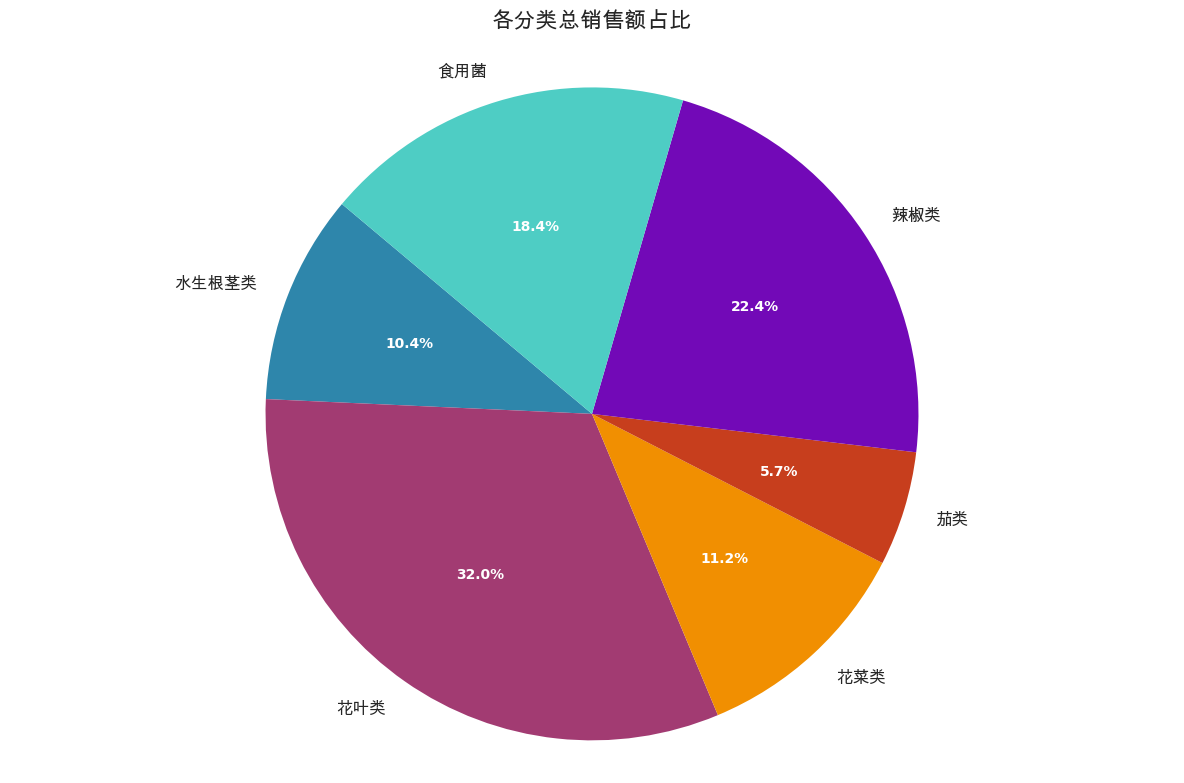

如果标签还是方块，下面提供备用方案：


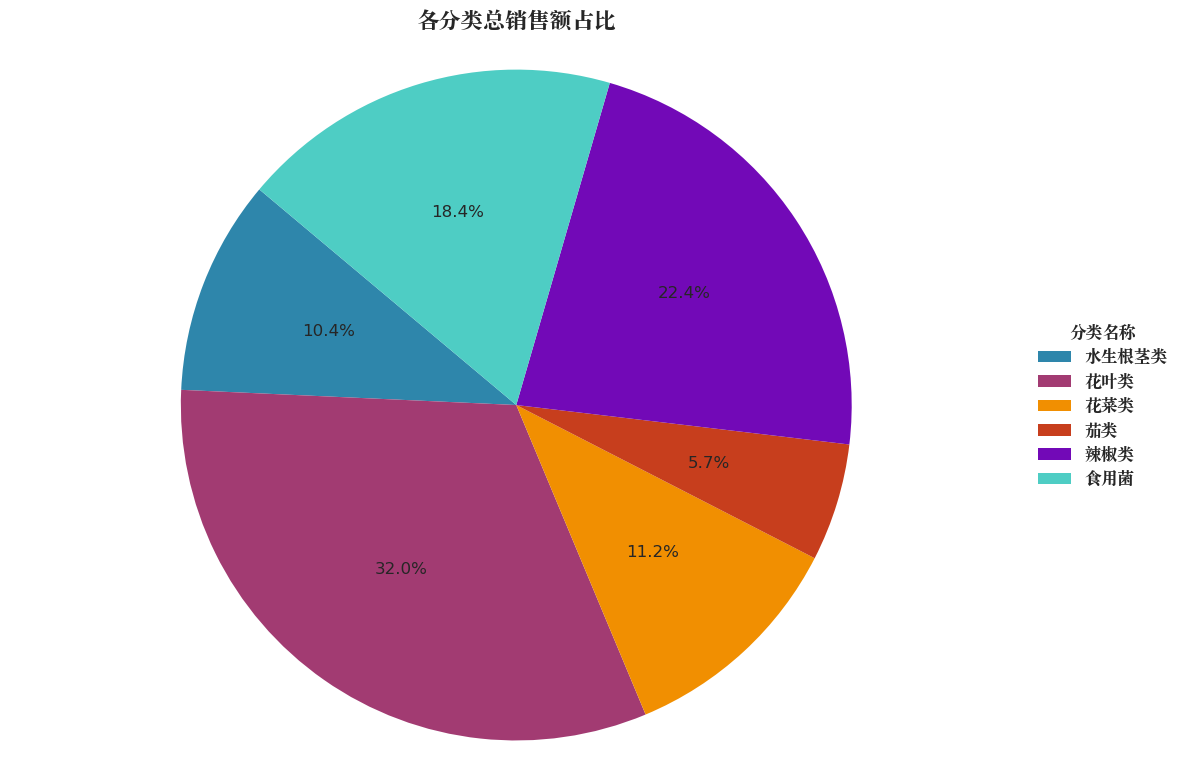


各分类总销售额详情：
水生根茎类: 350089.90元 (10.4%)
花叶类: 1079069.80元 (32.0%)
花菜类: 375751.70元 (11.2%)
茄类: 191124.26元 (5.7%)
辣椒类: 754133.02元 (22.4%)
食用菌: 619597.79元 (18.4%)

各分类总销售量占比分析


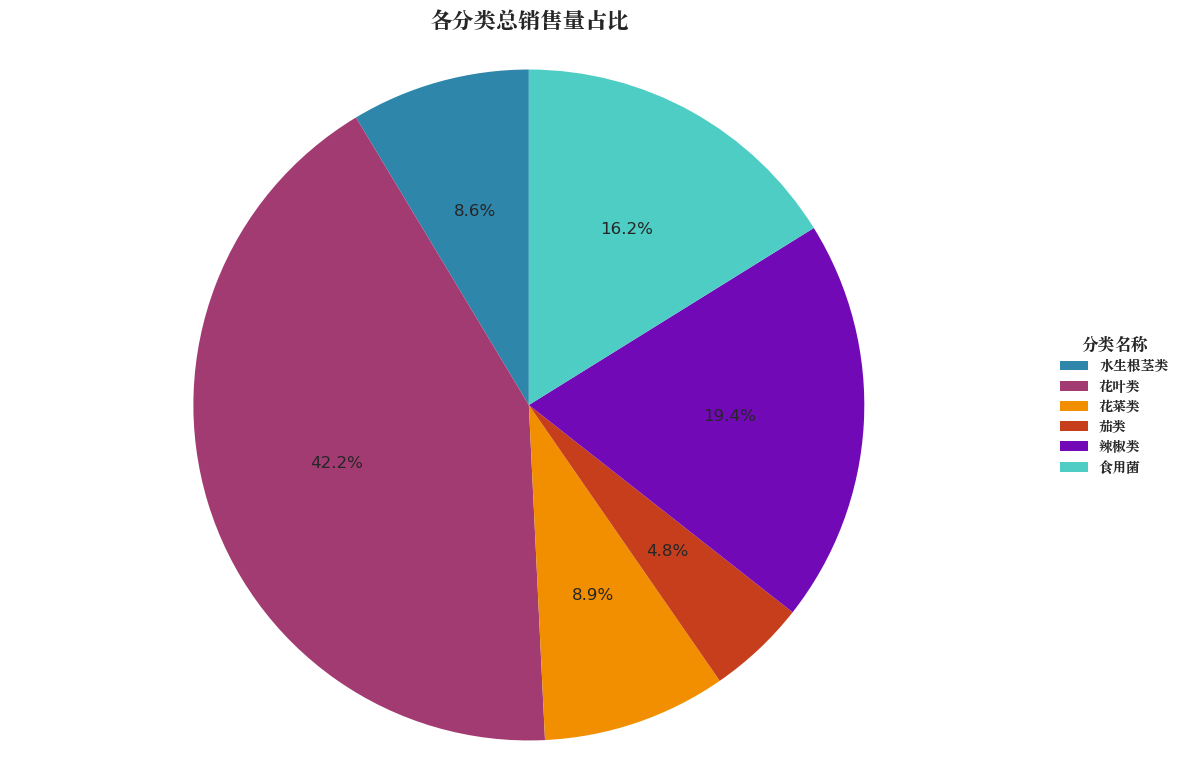


各分类总销售量详情：
水生根茎类: 40581.35千克 (8.6%)
花叶类: 198520.98千克 (42.2%)
花菜类: 41766.45千克 (8.9%)
茄类: 22431.78千克 (4.8%)
辣椒类: 91588.63千克 (19.4%)
食用菌: 76086.73千克 (16.2%)


In [59]:
# 统计df2 中分类名称的销售总量，日销售量均值，日销售额，总销售额等统计学特征
# 销售额需要通过销量乘以销售单价计算
df2_stats = df2.groupby(['分类名称']).agg(
    销售总量=('销量(千克)', 'sum'),
    日销售均值=('销量(千克)', 'mean'),
    日销售额=('销量(千克)', lambda x: (x * df2.loc[x.index, '销售单价(元/千克)']).mean()),
    总销售额=('销量(千克)', lambda x: (x * df2.loc[x.index, '销售单价(元/千克)']).sum())
).reset_index()

print(df2_stats)


# 将上述数据进行饼图可视化，要求配色符合科研风格
import matplotlib.pyplot as plt
import matplotlib.font_manager as fm
import platform

# 清除matplotlib字体缓存并重新加载
import matplotlib
# matplotlib.font_manager._rebuild()  # 此方法已不存在，无需调用

# 强制设置中文字体
plt.rcParams.update({
    'font.family': ['sans-serif'],
    'font.sans-serif': ['SimHei', 'DejaVu Sans', 'Arial Unicode MS', 'PingFang SC', 'Hiragino Sans GB'],
    'axes.unicode_minus': False,
    'font.size': 12
})

# 设置科研风格的配色方案
colors = ['#2E86AB', '#A23B72', '#F18F01', '#C73E1D', '#7209B7', '#4ECDC4']

# 绘制饼图
fig, ax = plt.subplots(figsize=(12, 8))

# 创建饼图 - 使用显式的字体设置
wedges, texts, autotexts = ax.pie(df2_stats['总销售额'], 
                                 labels=df2_stats['分类名称'], 
                                 autopct='%1.1f%%', 
                                 startangle=140,
                                 colors=colors)

# 强制设置每个文本的字体
for text in texts:
    text.set_fontfamily(['SimHei', 'DejaVu Sans', 'Arial Unicode MS', 'Songti SC'])
    text.set_fontsize(12)
    text.set_fontweight('bold')

for autotext in autotexts:
    autotext.set_color('white')
    autotext.set_fontsize(10)
    autotext.set_fontweight('bold')
    autotext.set_fontfamily(['SimHei', 'DejaVu Sans', 'Arial Unicode MS', 'Songti SC'])

# 设置标题
ax.set_title('各分类总销售额占比', fontsize=16, fontweight='bold', pad=20,
            fontfamily=['SimHei', 'DejaVu Sans', 'Arial Unicode MS', 'Songti SC'])

ax.axis('equal')  # 使饼图为圆形
plt.tight_layout()
plt.show()

# 如果上面还是显示方块，使用备用方案：不显示中文标签，改用图例
print("如果标签还是方块，下面提供备用方案：")

# 备用方案：使用图例而不是标签
fig2, ax2 = plt.subplots(figsize=(12, 8))

# 创建不带标签的饼图
wedges2, texts2, autotexts2 = ax2.pie(df2_stats['总销售额'], 
                                      autopct='%1.1f%%', 
                                      startangle=140,
                                      colors=colors)

# 添加图例
legend = ax2.legend(wedges2, df2_stats['分类名称'], 
          title="分类名称",
          loc="center left",
          bbox_to_anchor=(1, 0, 0.5, 1))

# 设置图例字体为 Songti SC
legend.get_title().set_fontfamily('Songti SC')
for text in legend.get_texts():
    text.set_fontfamily('Songti SC')

ax2.set_title('各分类总销售额占比', fontsize=16, fontweight='bold', fontfamily='Songti SC')
ax2.axis('equal')
plt.tight_layout()
plt.show()

# 同时显示数值
print("\n各分类总销售额详情：")
for i, row in df2_stats.iterrows():
    percentage = (row['总销售额'] / df2_stats['总销售额'].sum()) * 100
    print(f"{row['分类名称']}: {row['总销售额']:.2f}元 ({percentage:.1f}%)")

# 绘制总销售量占比饼图
print("\n" + "="*50)
print("各分类总销售量占比分析")
print("="*50)

# 使用图例方式绘制总销售量占比
fig3, ax3 = plt.subplots(figsize=(12, 8))

# 创建不带标签的饼图
wedges3, texts3, autotexts3 = ax3.pie(df2_stats['销售总量'], 
                                      autopct='%1.1f%%', 
                                      startangle=90,
                                      colors=colors)

# 添加图例
legend3 = ax3.legend(wedges3, df2_stats['分类名称'], 
          title="分类名称",
          loc="center left",
          bbox_to_anchor=(1, 0, 0.5, 1),
          fontsize=10)

# 设置图例字体为 Songti SC
legend3.get_title().set_fontfamily('Songti SC')
for text in legend3.get_texts():
    text.set_fontfamily('Songti SC')

ax3.set_title('各分类总销售量占比', fontsize=16, fontweight='bold', fontfamily='Songti SC')
ax3.axis('equal')
plt.tight_layout()
plt.show()

# 显示销售量详情
print("\n各分类总销售量详情：")
for i, row in df2_stats.iterrows():
    percentage = (row['销售总量'] / df2_stats['销售总量'].sum()) * 100
    print(f"{row['分类名称']}: {row['销售总量']:.2f}千克 ({percentage:.1f}%)")


各季节销售量占比分析
  销售季节        销售总量     日销售均值         总销售额
0   冬季  131189.635  0.588923  991995.1202
1   夏季  119396.852  0.487221  848870.3906
2   春季   97399.534  0.527828  676736.5731
3   秋季  122989.897  0.543830  852164.3929


/var/folders/cl/yslq0qr5729209j_yttkfpbr0000gn/T/ipykernel_6996/2026521619.py:57: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax5.set_xticklabels(season_stats['销售季节'], fontfamily='Songti SC')


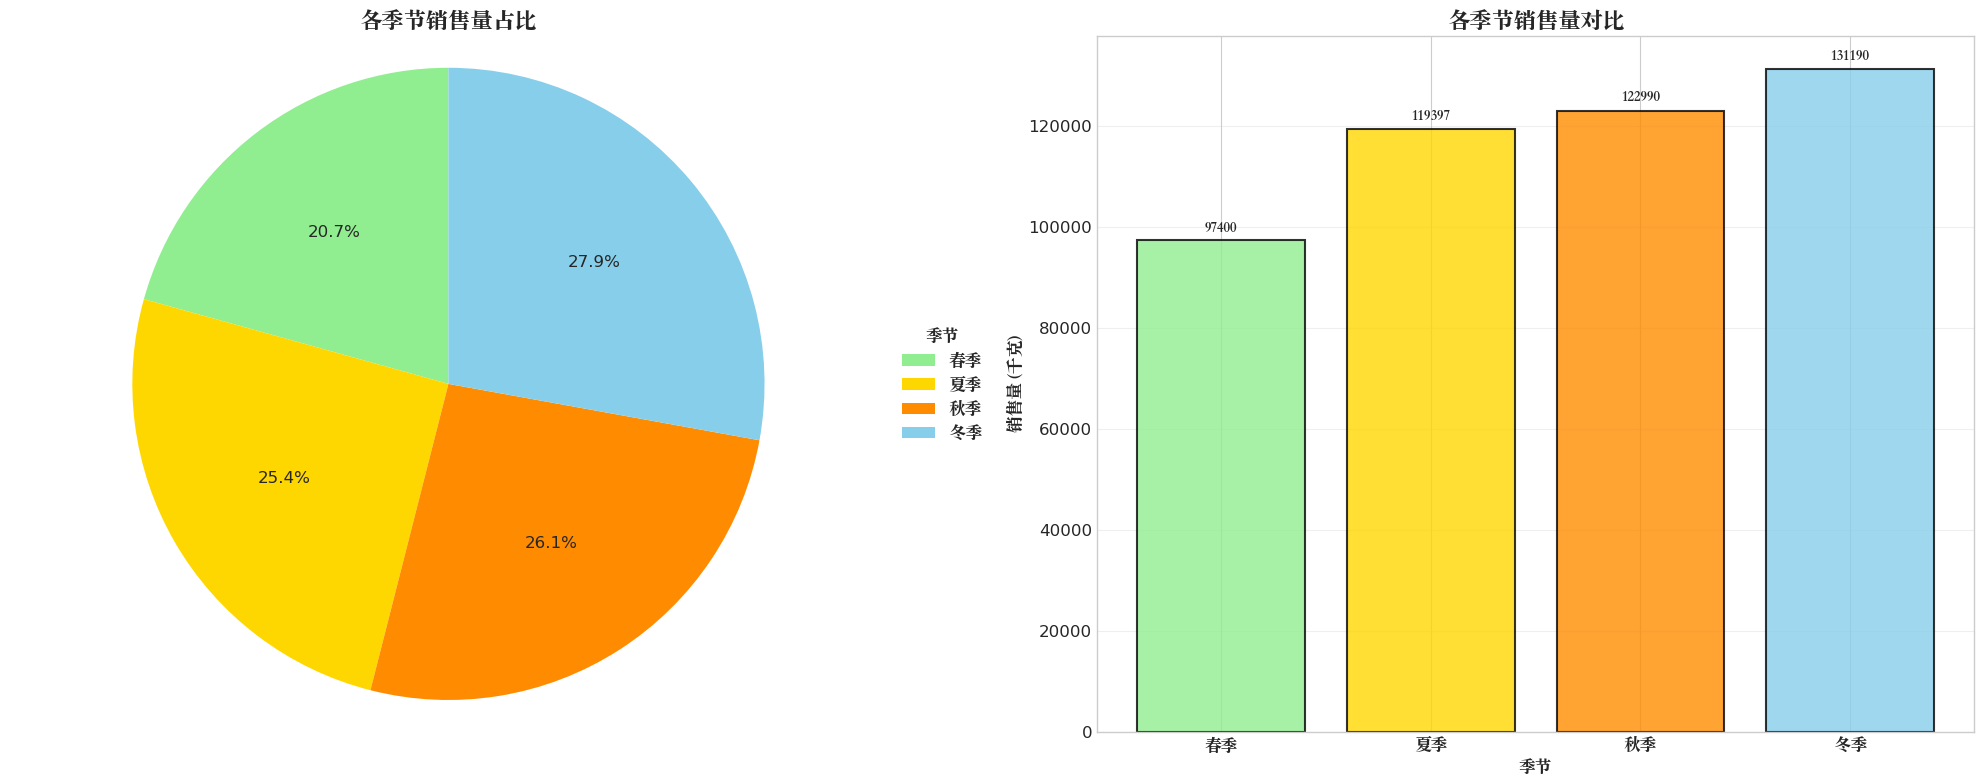


各季节销售量详情：
春季: 97399.53千克 (20.7%)
夏季: 119396.85千克 (25.4%)
秋季: 122989.90千克 (26.1%)
冬季: 131189.64千克 (27.9%)

各分类在不同季节的销售量分布热力图


/opt/anaconda3/envs/modeling/lib/python3.10/site-packages/seaborn/utils.py:61: UserWarning: Glyph 26149 (\N{CJK UNIFIED IDEOGRAPH-6625}) missing from font(s) DejaVu Sans.
  fig.canvas.draw()
/opt/anaconda3/envs/modeling/lib/python3.10/site-packages/seaborn/utils.py:61: UserWarning: Glyph 23395 (\N{CJK UNIFIED IDEOGRAPH-5B63}) missing from font(s) DejaVu Sans.
  fig.canvas.draw()
/opt/anaconda3/envs/modeling/lib/python3.10/site-packages/seaborn/utils.py:61: UserWarning: Glyph 22799 (\N{CJK UNIFIED IDEOGRAPH-590F}) missing from font(s) DejaVu Sans.
  fig.canvas.draw()
/opt/anaconda3/envs/modeling/lib/python3.10/site-packages/seaborn/utils.py:61: UserWarning: Glyph 31179 (\N{CJK UNIFIED IDEOGRAPH-79CB}) missing from font(s) DejaVu Sans.
  fig.canvas.draw()
/opt/anaconda3/envs/modeling/lib/python3.10/site-packages/seaborn/utils.py:61: UserWarning: Glyph 20908 (\N{CJK UNIFIED IDEOGRAPH-51AC}) missing from font(s) DejaVu Sans.
  fig.canvas.draw()
/opt/anaconda3/envs/modeling/lib/python3.10/s

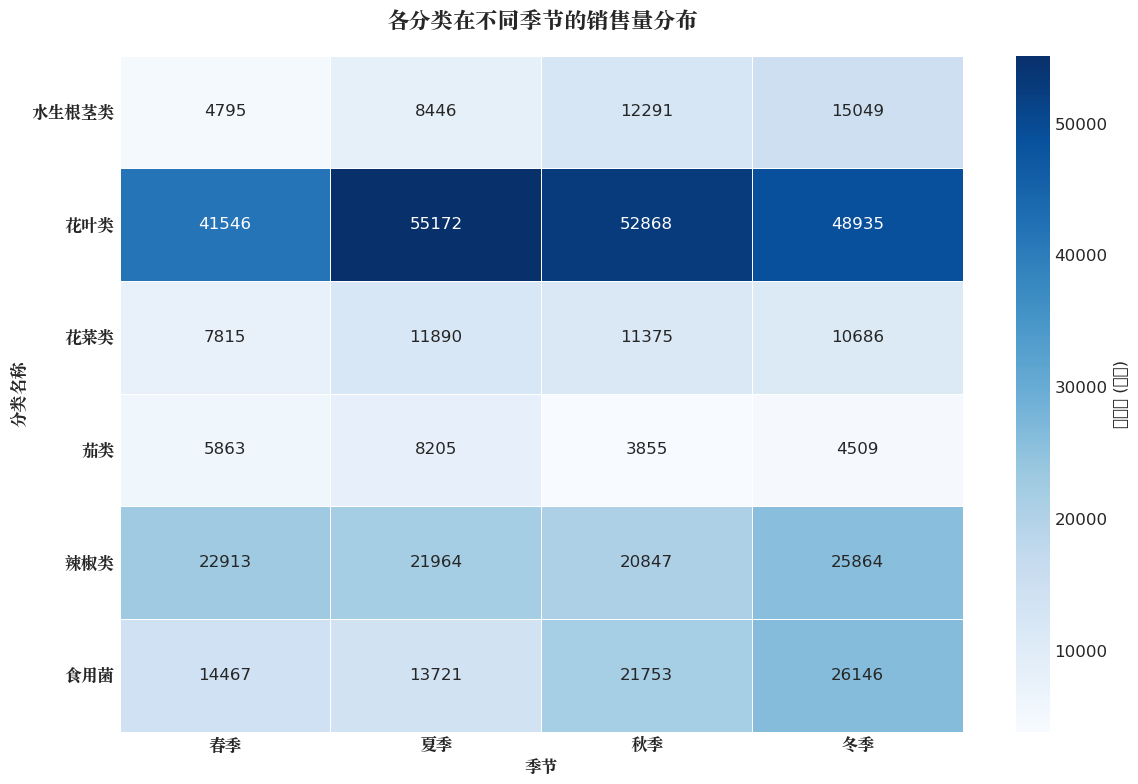


各分类在不同季节的销售量详情：
销售季节         春季        夏季        秋季        冬季
分类名称                                         
水生根茎类   4794.96   8445.69  12291.23  15049.47
花叶类    41546.12  55171.80  52868.35  48934.71
花菜类     7815.23  11890.34  11375.21  10685.67
茄类      5862.96   8204.91   3854.52   4509.40
辣椒类    22913.32  21963.59  20847.27  25864.45
食用菌    14466.96  13720.53  21753.31  26145.93


In [60]:
# 分析各个季节的销售量占比
print("\n" + "="*50)
print("各季节销售量占比分析")
print("="*50)

# 统计各季节销售量
season_stats = df2.groupby(['销售季节']).agg(
    销售总量=('销量(千克)', 'sum'),
    日销售均值=('销量(千克)', 'mean'),
    总销售额=('销量(千克)', lambda x: (x * df2.loc[x.index, '销售单价(元/千克)']).sum())
).reset_index()

print(season_stats)

# 季节排序（确保按照春夏秋冬的顺序）
season_order = ['春季', '夏季', '秋季', '冬季']
season_stats['销售季节'] = pd.Categorical(season_stats['销售季节'], categories=season_order, ordered=True)
season_stats = season_stats.sort_values('销售季节').reset_index(drop=True)

# 设置季节配色方案
season_colors = ['#90EE90', '#FFD700', '#FF8C00', '#87CEEB']  # 春绿、夏黄、秋橙、冬蓝

# 1. 绘制季节销售量饼图
fig4, (ax4, ax5) = plt.subplots(1, 2, figsize=(20, 8))

# 饼图
wedges4, texts4, autotexts4 = ax4.pie(season_stats['销售总量'], 
                                      autopct='%1.1f%%', 
                                      startangle=90,
                                      colors=season_colors)

# 添加图例
legend4 = ax4.legend(wedges4, season_stats['销售季节'], 
          title="季节",
          loc="center left",
          bbox_to_anchor=(1, 0, 0.5, 1),
          fontsize=12)

# 设置图例字体为 Songti SC
legend4.get_title().set_fontfamily('Songti SC')
for text in legend4.get_texts():
    text.set_fontfamily('Songti SC')

ax4.set_title('各季节销售量占比', fontsize=16, fontweight='bold', fontfamily='Songti SC')
ax4.axis('equal')

# 2. 绘制季节销售量柱状图
bars = ax5.bar(season_stats['销售季节'], season_stats['销售总量'], 
               color=season_colors, alpha=0.8, edgecolor='black', linewidth=1.5)

ax5.set_title('各季节销售量对比', fontsize=16, fontweight='bold', fontfamily='Songti SC')
ax5.set_xlabel('季节', fontsize=12, fontfamily='Songti SC')
ax5.set_ylabel('销售量 (千克)', fontsize=12, fontfamily='Songti SC')
ax5.grid(axis='y', alpha=0.3)

# 设置坐标轴标签字体为 Songti SC
ax5.set_xticklabels(season_stats['销售季节'], fontfamily='Songti SC')

# 在柱状图上添加数值标签
for bar, value in zip(bars, season_stats['销售总量']):
    height = bar.get_height()
    ax5.text(bar.get_x() + bar.get_width()/2., height + height*0.01,
             f'{value:.0f}', ha='center', va='bottom', fontsize=10, fontweight='bold', fontfamily='Songti SC')

plt.tight_layout()
plt.show()

# 显示季节销售详情
print("\n各季节销售量详情：")
for i, row in season_stats.iterrows():
    percentage = (row['销售总量'] / season_stats['销售总量'].sum()) * 100
    print(f"{row['销售季节']}: {row['销售总量']:.2f}千克 ({percentage:.1f}%)")

# 绘制各分类在不同季节的销售量热力图
import seaborn as sns

print("\n" + "="*50)
print("各分类在不同季节的销售量分布热力图")
print("="*50)

# 创建分类-季节的交叉表
season_category_stats = df2.groupby(['销售季节', '分类名称'])['销量(千克)'].sum().reset_index()
pivot_table = season_category_stats.pivot(index='分类名称', columns='销售季节', values='销量(千克)')

# 确保季节按照正确顺序排列
pivot_table = pivot_table.reindex(columns=season_order)

# 绘制热力图
plt.figure(figsize=(12, 8))
ax_heatmap = sns.heatmap(pivot_table, 
            annot=True, 
            fmt='.0f', 
            cmap='Blues',
            cbar_kws={'label': '销售量 (千克)'},
            linewidths=0.5)

plt.title('各分类在不同季节的销售量分布', fontsize=16, fontweight='bold', pad=20, fontfamily='Songti SC')
plt.xlabel('季节', fontsize=12, fontfamily='Songti SC')
plt.ylabel('分类名称', fontsize=12, fontfamily='Songti SC')

# 设置坐标轴标签字体
ax_heatmap.set_xticklabels(ax_heatmap.get_xticklabels(), fontfamily='Songti SC')
ax_heatmap.set_yticklabels(ax_heatmap.get_yticklabels(), fontfamily='Songti SC')

plt.xticks(rotation=0)
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

# 显示具体数值
print("\n各分类在不同季节的销售量详情：")
print(pivot_table.round(2))


三维柱状图：分类名称 vs 季节 vs 销售额
各分类在不同季节的销售额:
销售季节          春季         夏季         秋季         冬季
分类名称                                             
水生根茎类   47142.11   83992.50   92751.23  126204.06
花叶类    226024.26  325172.48  295459.04  232414.02
花菜类     65999.36  110815.22  106114.14   92822.99
茄类      51900.40   56913.78   30465.44   51844.64
辣椒类    179749.31  147767.64  150971.62  275644.46
食用菌    105921.13  124208.78  176402.93  213064.96


/var/folders/cl/yslq0qr5729209j_yttkfpbr0000gn/T/ipykernel_6996/2840543290.py:11: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  season_category_sales = df2.groupby(['销售季节', '分类名称']).apply(
/var/folders/cl/yslq0qr5729209j_yttkfpbr0000gn/T/ipykernel_6996/2840543290.py:87: UserWarning: Tight layout not applied. The left and right margins cannot be made large enough to accommodate all Axes decorations.
  plt.tight_layout()


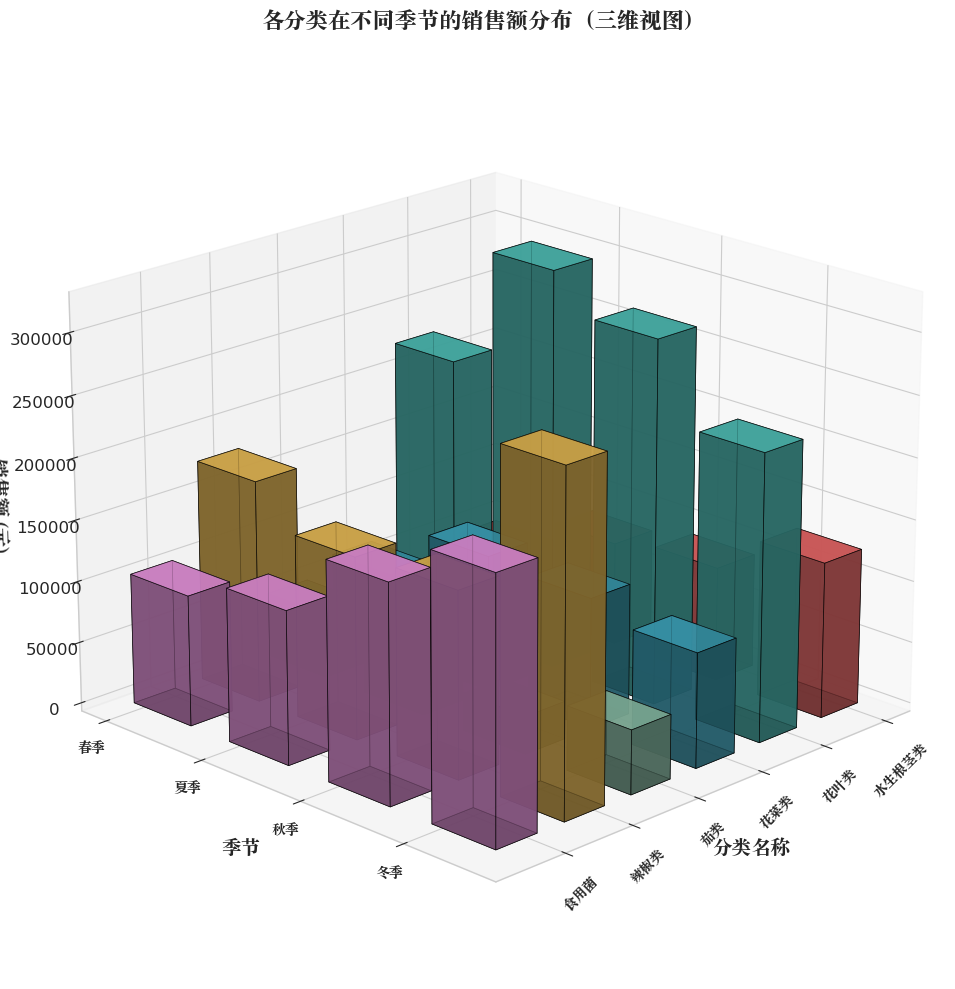

/var/folders/cl/yslq0qr5729209j_yttkfpbr0000gn/T/ipykernel_6996/2840543290.py:142: UserWarning: Tight layout not applied. The left and right margins cannot be made large enough to accommodate all Axes decorations.
  plt.tight_layout()


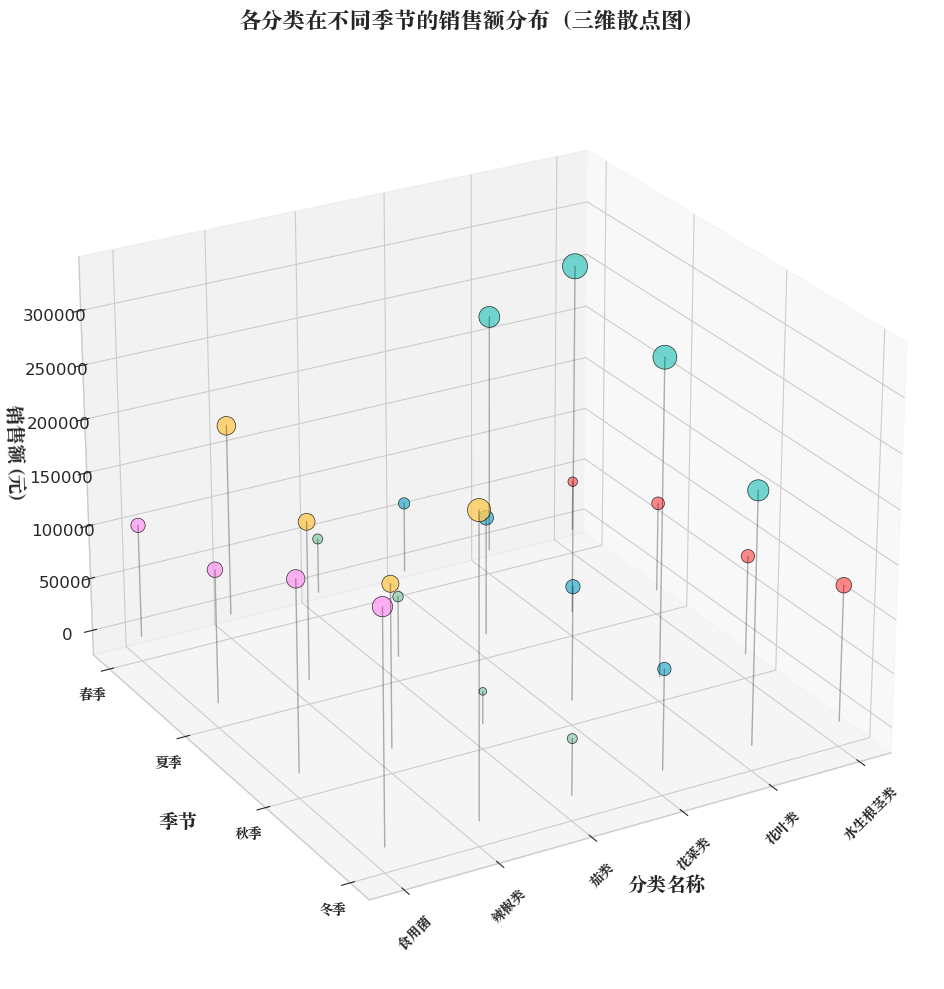


销售额分析：
最高销售额组合: 花叶类 - 夏季, 销售额: 325172.48元
最低销售额组合: 茄类 - 秋季, 销售额: 30465.44元


In [61]:
# 制作三维柱状图：x轴为分类名称，y轴为季节，z轴为销售额
print("\n" + "="*50)
print("三维柱状图：分类名称 vs 季节 vs 销售额")
print("="*50)

from mpl_toolkits.mplot3d import Axes3D
import numpy as np

# 准备三维数据
# 计算各分类在不同季节的销售额
season_category_sales = df2.groupby(['销售季节', '分类名称']).apply(
    lambda x: (x['销量(千克)'] * x['销售单价(元/千克)']).sum()
).reset_index()
season_category_sales.columns = ['销售季节', '分类名称', '销售额']

# 创建分类-季节的销售额透视表
sales_pivot = season_category_sales.pivot(index='分类名称', columns='销售季节', values='销售额')
sales_pivot = sales_pivot.reindex(columns=season_order).fillna(0)

print("各分类在不同季节的销售额:")
print(sales_pivot.round(2))

# 设置三维图形
fig = plt.figure(figsize=(16, 12))
ax = fig.add_subplot(111, projection='3d')

# 准备数据
categories = sales_pivot.index.tolist()
seasons = sales_pivot.columns.tolist()
n_categories = len(categories)
n_seasons = len(seasons)

# 创建网格
xpos = np.arange(n_categories)
ypos = np.arange(n_seasons)
xposM, yposM = np.meshgrid(xpos, ypos, indexing="ij")

# 展平数据以便绘图
xpos_flat = xposM.ravel()
ypos_flat = yposM.ravel()
zpos = np.zeros_like(xpos_flat)

# 获取销售额数据
dx = dy = 0.6  # 柱子的宽度
dz = []
colors_3d = []

# 为每个分类设置不同的颜色
category_colors = ['#FF6B6B', '#4ECDC4', '#45B7D1', '#96CEB4', '#FECA57', '#FF9FF3']
season_alpha = [0.6, 0.7, 0.8, 0.9]  # 不同季节的透明度

for i, category in enumerate(categories):
    for j, season in enumerate(seasons):
        value = sales_pivot.loc[category, season]
        dz.append(value)
        # 根据分类和季节设置颜色
        base_color = category_colors[i % len(category_colors)]
        alpha = season_alpha[j % len(season_alpha)]
        colors_3d.append(base_color)

# 绘制三维柱状图
bars = ax.bar3d(xpos_flat, ypos_flat, zpos, dx, dy, dz, 
                color=colors_3d, alpha=0.8, edgecolor='black', linewidth=0.5)

# 设置坐标轴标签
ax.set_xlabel('分类名称', fontsize=14, fontfamily='Songti SC', labelpad=10)
ax.set_ylabel('季节', fontsize=14, fontfamily='Songti SC', labelpad=10)
ax.set_zlabel('销售额 (元)', fontsize=14, fontfamily='Songti SC', labelpad=10)

# 设置刻度标签
ax.set_xticks(range(n_categories))
ax.set_xticklabels(categories, fontfamily='Songti SC', fontsize=10, rotation=45)
ax.set_yticks(range(n_seasons))
ax.set_yticklabels(seasons, fontfamily='Songti SC', fontsize=10)

# 设置标题
ax.set_title('各分类在不同季节的销售额分布（三维视图）', 
             fontsize=16, fontweight='bold', fontfamily='Songti SC', pad=20)

# 调整视角
ax.view_init(elev=20, azim=45)

# 添加网格
ax.grid(True, alpha=0.3)

# 调整布局
plt.tight_layout()
plt.show()

# 制作另一个更清晰的三维散点图版本
fig2 = plt.figure(figsize=(16, 12))
ax2 = fig2.add_subplot(111, projection='3d')

# 准备散点图数据
x_scatter = []
y_scatter = []
z_scatter = []
colors_scatter = []
sizes = []

for i, category in enumerate(categories):
    for j, season in enumerate(seasons):
        value = sales_pivot.loc[category, season]
        if value > 0:  # 只显示有销售额的数据点
            x_scatter.append(i)
            y_scatter.append(j)
            z_scatter.append(value)
            colors_scatter.append(category_colors[i % len(category_colors)])
            sizes.append(value / 1000)  # 根据销售额调整点的大小

# 绘制三维散点图
scatter = ax2.scatter(x_scatter, y_scatter, z_scatter, 
                     c=colors_scatter, s=sizes, alpha=0.8, 
                     edgecolors='black', linewidth=0.5)

# 添加柱子连接到底面
for x, y, z in zip(x_scatter, y_scatter, z_scatter):
    ax2.plot([x, x], [y, y], [0, z], 'k-', alpha=0.3, linewidth=1)

# 设置坐标轴标签
ax2.set_xlabel('分类名称', fontsize=14, fontfamily='Songti SC', labelpad=10)
ax2.set_ylabel('季节', fontsize=14, fontfamily='Songti SC', labelpad=10)
ax2.set_zlabel('销售额 (元)', fontsize=14, fontfamily='Songti SC', labelpad=10)

# 设置刻度标签
ax2.set_xticks(range(n_categories))
ax2.set_xticklabels(categories, fontfamily='Songti SC', fontsize=10, rotation=45)
ax2.set_yticks(range(n_seasons))
ax2.set_yticklabels(seasons, fontfamily='Songti SC', fontsize=10)

# 设置标题
ax2.set_title('各分类在不同季节的销售额分布（三维散点图）', 
              fontsize=16, fontweight='bold', fontfamily='Songti SC', pad=20)

# 调整视角
ax2.view_init(elev=25, azim=60)

# 添加网格
ax2.grid(True, alpha=0.3)

# 调整布局
plt.tight_layout()
plt.show()

# 显示最高和最低销售额的组合
print("\n销售额分析：")
max_sales = season_category_sales.loc[season_category_sales['销售额'].idxmax()]
min_sales = season_category_sales.loc[season_category_sales['销售额'].idxmin()]

print(f"最高销售额组合: {max_sales['分类名称']} - {max_sales['销售季节']}, 销售额: {max_sales['销售额']:.2f}元")
print(f"最低销售额组合: {min_sales['分类名称']} - {min_sales['销售季节']}, 销售额: {min_sales['销售额']:.2f}元")


单品编码销售量聚类分析 - 受欢迎程度分级
共有 246 个不同的单品编码

销售量统计概览:
count      246.000000
mean      1914.536252
std       4199.916020
min          0.415000
25%         16.860000
50%        257.096000
75%       1560.849500
max      28164.331000
Name: 总销售量, dtype: float64

聚类结果分析:
--------------------------------------------------
不受欢迎:
  - 单品数量: 212.0
  - 平均销售量: 588.28 千克
  - 销售量范围: 0.41 - 4229.00 千克

受欢迎:
  - 单品数量: 30.0
  - 平均销售量: 8140.74 千克
  - 销售量范围: 4496.72 - 15910.46 千克

普通:
  - 单品数量: 4.0
  - 平均销售量: 25509.55 千克
  - 销售量范围: 19187.22 - 28164.33 千克

共有 246 个不同的单品编码

销售量统计概览:
count      246.000000
mean      1914.536252
std       4199.916020
min          0.415000
25%         16.860000
50%        257.096000
75%       1560.849500
max      28164.331000
Name: 总销售量, dtype: float64

聚类结果分析:
--------------------------------------------------
不受欢迎:
  - 单品数量: 212.0
  - 平均销售量: 588.28 千克
  - 销售量范围: 0.41 - 4229.00 千克

受欢迎:
  - 单品数量: 30.0
  - 平均销售量: 8140.74 千克
  - 销售量范围: 4496.72 - 15910.46 千克

普通:
  - 单品数量: 4.0
  - 平均销

/var/folders/cl/yslq0qr5729209j_yttkfpbr0000gn/T/ipykernel_6996/3265065704.py:97: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  box_plot = ax2.boxplot(box_data, labels=popularity_order, patch_artist=True)


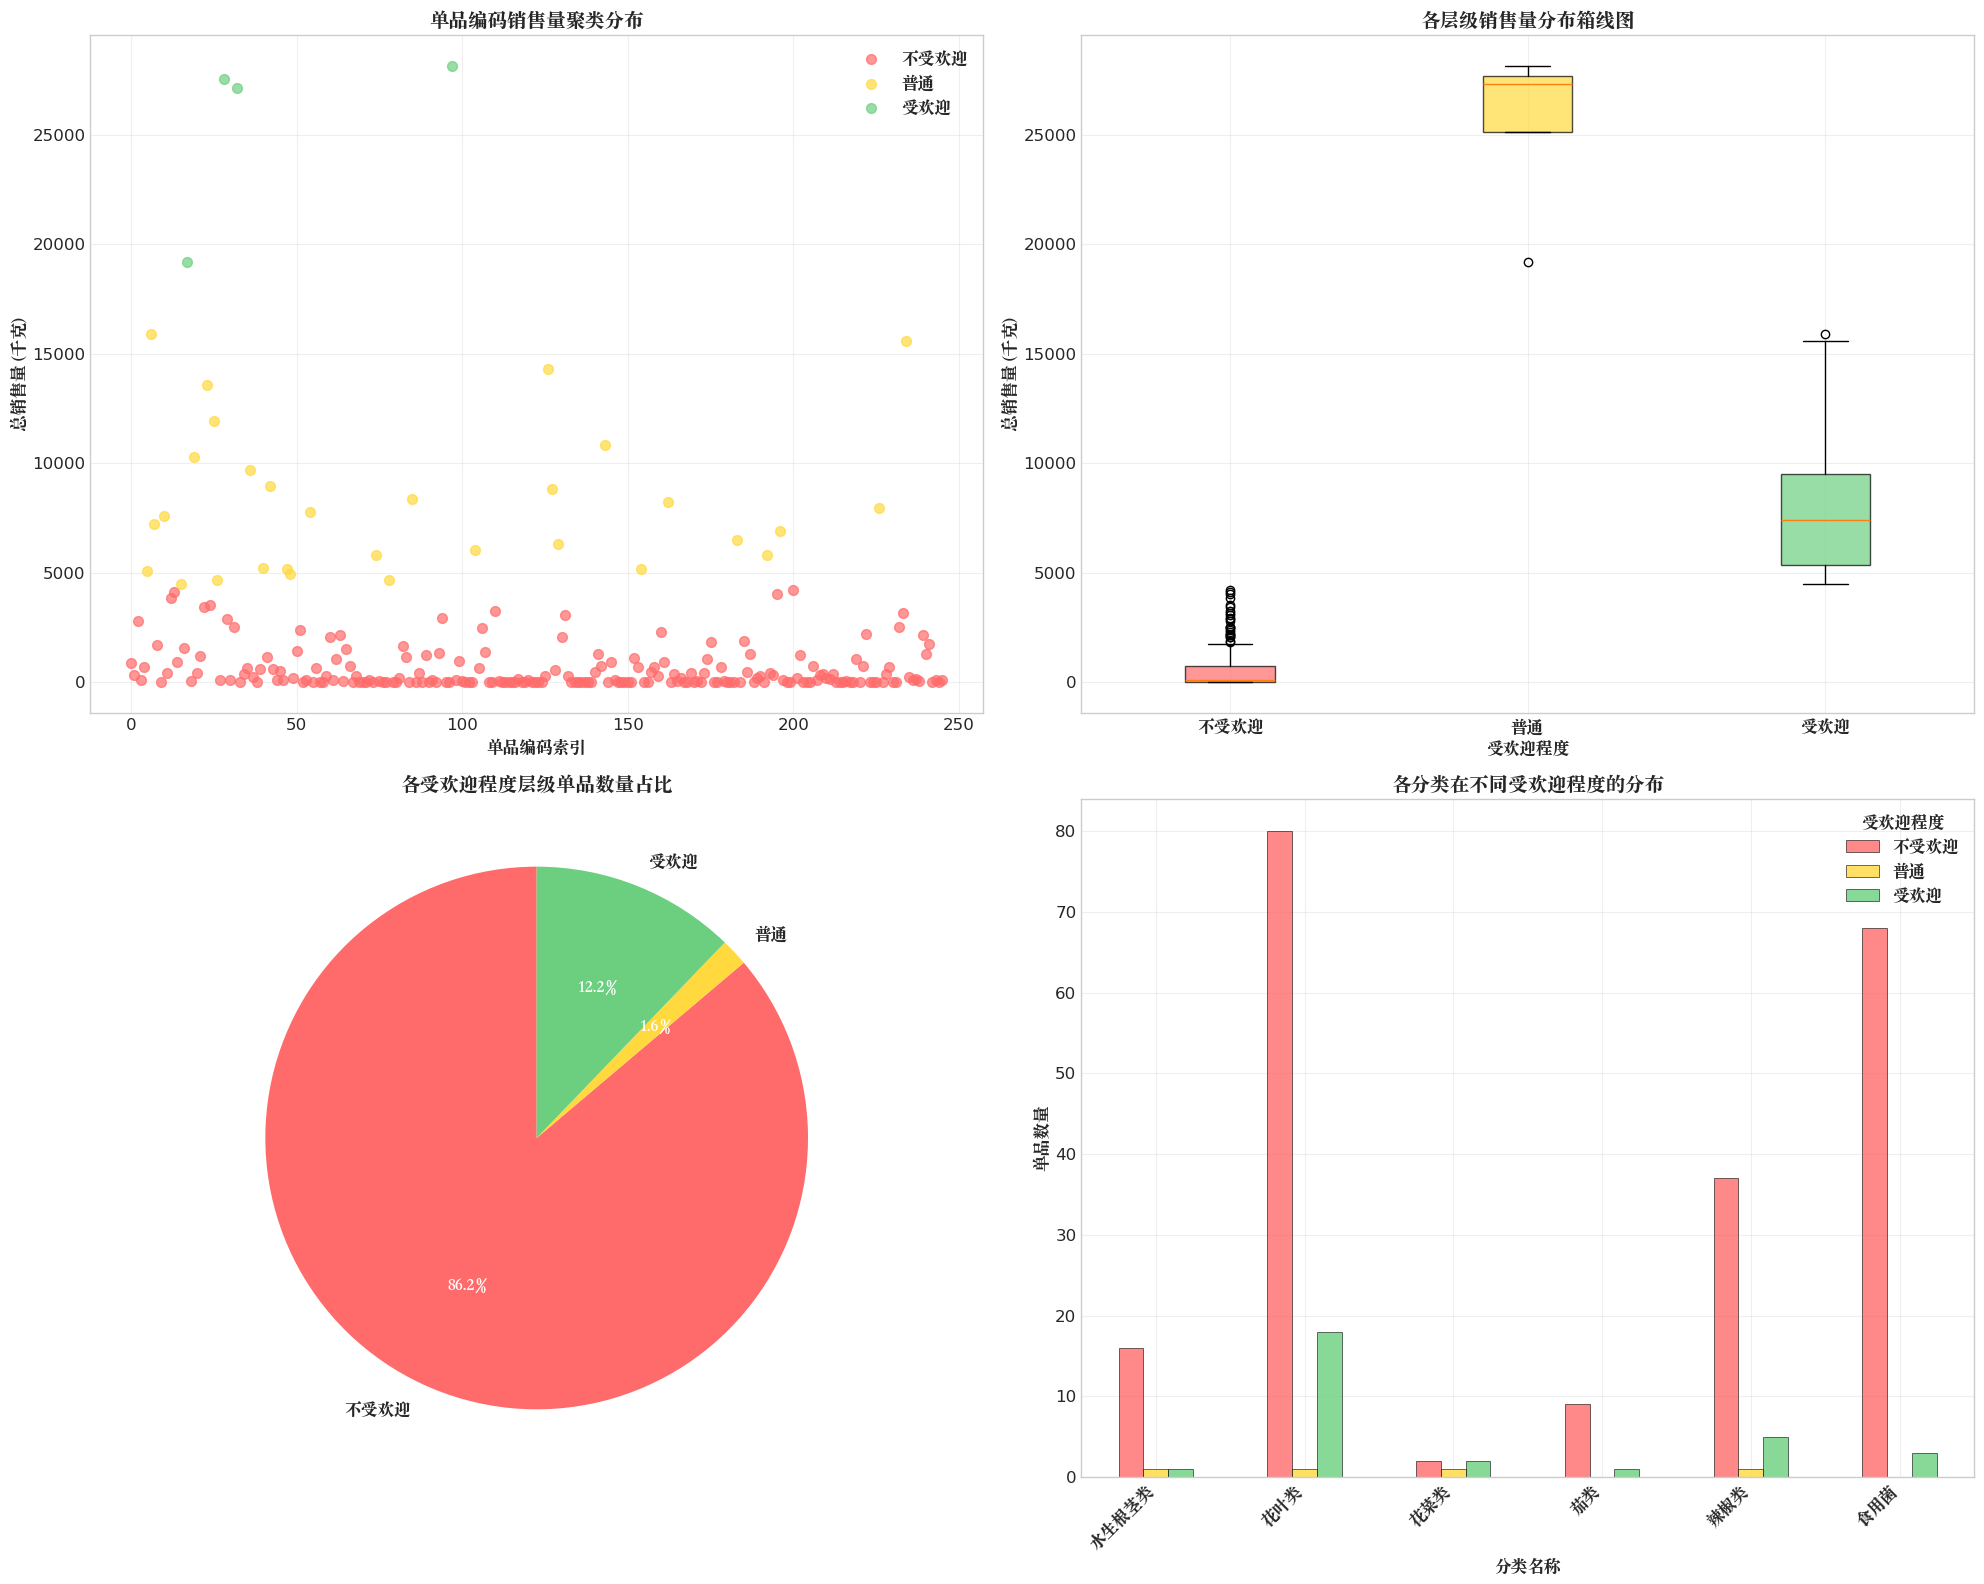


各受欢迎程度层级详细统计:

不受欢迎 (212个单品):
  总销售量统计:
    - 平均值: 588.28 千克
    - 中位数: 105.50 千克
    - 标准差: 935.35 千克
    - 范围: 0.41 - 4229.00 千克
  分类分布:
    - 花叶类: 80个单品
    - 食用菌: 68个单品
    - 辣椒类: 37个单品
    - 水生根茎类: 16个单品
    - 茄类: 9个单品
    - 花菜类: 2个单品

普通 (4个单品):
  总销售量统计:
    - 平均值: 25509.55 千克
    - 中位数: 27343.33 千克
    - 标准差: 4235.58 千克
    - 范围: 19187.22 - 28164.33 千克
  分类分布:
    - 花叶类: 1个单品
    - 花菜类: 1个单品
    - 水生根茎类: 1个单品
    - 辣椒类: 1个单品

受欢迎 (30个单品):
  总销售量统计:
    - 平均值: 8140.74 千克
    - 中位数: 7423.76 千克
    - 标准差: 3324.12 千克
    - 范围: 4496.72 - 15910.46 千克
  分类分布:
    - 花叶类: 18个单品
    - 辣椒类: 5个单品
    - 食用菌: 3个单品
    - 花菜类: 2个单品
    - 茄类: 1个单品
    - 水生根茎类: 1个单品

聚类分析完成！共分析了246个单品编码
聚类结果已保存在 product_sales 变量中

各层级代表性单品示例:

不受欢迎层级 (前5个单品):
           单品编码 分类名称     总销售量  销售次数       销售总额
102900011034330  食用菌 4229.000  4232 22604.9000
102900005115878  花叶类 4110.162 10128 26871.0422
102900011034224  花叶类 4057.000  4058 12220.0000
102900005115861  花叶类 3836.566  8022 15172.1753
102900005116509   茄类 

In [62]:
# 对df2中单品编码的总销售量进行聚类分析，划分为3个层级
print("\n" + "="*60)
print("单品编码销售量聚类分析 - 受欢迎程度分级")
print("="*60)

from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler
import numpy as np

# 统计各单品编码的总销售量
product_sales = df2.groupby('单品编码').agg(
    总销售量=('销量(千克)', 'sum'),
    销售次数=('销量(千克)', 'count'),
    平均单次销量=('销量(千克)', 'mean'),
    销售总额=('销量(千克)', lambda x: (x * df2.loc[x.index, '销售单价(元/千克)']).sum()),
    分类名称=('分类名称', 'first')
).reset_index()

print(f"共有 {len(product_sales)} 个不同的单品编码")
print("\n销售量统计概览:")
print(product_sales['总销售量'].describe())

# 准备聚类数据 - 使用总销售量进行聚类
X = product_sales[['总销售量']].values

# 标准化数据
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# 使用K-means聚类，分为3个层级
kmeans = KMeans(n_clusters=3, random_state=42, n_init=10)
clusters = kmeans.fit_predict(X_scaled)

# 将聚类结果添加到数据中
product_sales['cluster'] = clusters

# 计算各聚类的中心点（原始尺度）
cluster_centers = scaler.inverse_transform(kmeans.cluster_centers_)
cluster_info = []

for i in range(3):
    cluster_data = product_sales[product_sales['cluster'] == i]
    cluster_info.append({
        'cluster': i,
        'count': len(cluster_data),
        'avg_sales': cluster_data['总销售量'].mean(),
        'min_sales': cluster_data['总销售量'].min(),
        'max_sales': cluster_data['总销售量'].max(),
        'center': cluster_centers[i][0]
    })

# 根据平均销售量对聚类进行排序，并分配标签
cluster_info_df = pd.DataFrame(cluster_info)
cluster_info_df = cluster_info_df.sort_values('avg_sales')

# 分配受欢迎程度标签
popularity_labels = ['不受欢迎', '普通', '受欢迎']
cluster_mapping = {}
for idx, row in cluster_info_df.iterrows():
    cluster_mapping[row['cluster']] = popularity_labels[idx]

# 应用标签映射
product_sales['受欢迎程度'] = product_sales['cluster'].map(cluster_mapping)

print("\n聚类结果分析:")
print("-" * 50)
for idx, row in cluster_info_df.iterrows():
    label = popularity_labels[idx]
    original_cluster = row['cluster']
    print(f"{label}:")
    print(f"  - 单品数量: {row['count']}")
    print(f"  - 平均销售量: {row['avg_sales']:.2f} 千克")
    print(f"  - 销售量范围: {row['min_sales']:.2f} - {row['max_sales']:.2f} 千克")
    print()

# 可视化聚类结果
fig, ((ax1, ax2), (ax3, ax4)) = plt.subplots(2, 2, figsize=(20, 16))

# 1. 散点图显示聚类结果
colors_cluster = ['#FF6B6B', '#FFD93D', '#6BCF7F']  # 红、黄、绿
for i, (cluster_id, label) in enumerate(zip(cluster_info_df['cluster'], popularity_labels)):
    cluster_data = product_sales[product_sales['cluster'] == cluster_id]
    ax1.scatter(cluster_data.index, cluster_data['总销售量'], 
               c=colors_cluster[i], label=label, alpha=0.7, s=50)

ax1.set_xlabel('单品编码索引', fontsize=12, fontfamily='Songti SC')
ax1.set_ylabel('总销售量 (千克)', fontsize=12, fontfamily='Songti SC')
ax1.set_title('单品编码销售量聚类分布', fontsize=14, fontweight='bold', fontfamily='Songti SC')
legend1 = ax1.legend()
for text in legend1.get_texts():
    text.set_fontfamily('Songti SC')
ax1.grid(True, alpha=0.3)

# 2. 箱线图显示各层级的销售量分布
popularity_order = ['不受欢迎', '普通', '受欢迎']
box_data = [product_sales[product_sales['受欢迎程度'] == label]['总销售量'] for label in popularity_order]
box_plot = ax2.boxplot(box_data, labels=popularity_order, patch_artist=True)

for patch, color in zip(box_plot['boxes'], colors_cluster):
    patch.set_facecolor(color)
    patch.set_alpha(0.7)

ax2.set_xlabel('受欢迎程度', fontsize=12, fontfamily='Songti SC')
ax2.set_ylabel('总销售量 (千克)', fontsize=12, fontfamily='Songti SC')
ax2.set_title('各层级销售量分布箱线图', fontsize=14, fontweight='bold', fontfamily='Songti SC')
ax2.set_xticklabels(popularity_order, fontfamily='Songti SC')
ax2.grid(True, alpha=0.3)

# 3. 各层级单品数量饼图
popularity_counts = product_sales['受欢迎程度'].value_counts().reindex(popularity_order)
wedges3, texts3, autotexts3 = ax3.pie(popularity_counts.values, 
                                      labels=popularity_counts.index,
                                      autopct='%1.1f%%',
                                      colors=colors_cluster,
                                      startangle=90)

for text in texts3:
    text.set_fontfamily('Songti SC')
    text.set_fontsize(12)

for autotext in autotexts3:
    autotext.set_fontfamily('Songti SC')
    autotext.set_color('white')
    autotext.set_fontweight('bold')

ax3.set_title('各受欢迎程度层级单品数量占比', fontsize=14, fontweight='bold', fontfamily='Songti SC')

# 4. 各分类名称在不同受欢迎程度的分布
category_popularity = pd.crosstab(product_sales['分类名称'], product_sales['受欢迎程度'])
category_popularity = category_popularity.reindex(columns=popularity_order, fill_value=0)

category_popularity.plot(kind='bar', ax=ax4, color=colors_cluster, 
                        alpha=0.8, edgecolor='black', linewidth=0.5)
ax4.set_xlabel('分类名称', fontsize=12, fontfamily='Songti SC')
ax4.set_ylabel('单品数量', fontsize=12, fontfamily='Songti SC')
ax4.set_title('各分类在不同受欢迎程度的分布', fontsize=14, fontweight='bold', fontfamily='Songti SC')
ax4.set_xticklabels(category_popularity.index, rotation=45, ha='right', fontfamily='Songti SC')
legend4 = ax4.legend(title='受欢迎程度')
legend4.get_title().set_fontfamily('Songti SC')
for text in legend4.get_texts():
    text.set_fontfamily('Songti SC')
ax4.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

# 显示各层级的详细统计
print("\n各受欢迎程度层级详细统计:")
print("=" * 60)
for level in popularity_order:
    level_data = product_sales[product_sales['受欢迎程度'] == level]
    print(f"\n{level} ({len(level_data)}个单品):")
    print(f"  总销售量统计:")
    print(f"    - 平均值: {level_data['总销售量'].mean():.2f} 千克")
    print(f"    - 中位数: {level_data['总销售量'].median():.2f} 千克")
    print(f"    - 标准差: {level_data['总销售量'].std():.2f} 千克")
    print(f"    - 范围: {level_data['总销售量'].min():.2f} - {level_data['总销售量'].max():.2f} 千克")
    print(f"  分类分布:")
    category_dist = level_data['分类名称'].value_counts()
    for cat, count in category_dist.items():
        print(f"    - {cat}: {count}个单品")

# 保存聚类结果
product_sales_sorted = product_sales.sort_values('总销售量', ascending=False)
print(f"\n聚类分析完成！共分析了{len(product_sales)}个单品编码")
print("聚类结果已保存在 product_sales 变量中")

# 显示每个层级的前5个单品示例
print("\n各层级代表性单品示例:")
print("=" * 60)
for level in popularity_order:
    level_data = product_sales[product_sales['受欢迎程度'] == level].sort_values('总销售量', ascending=False)
    print(f"\n{level}层级 (前5个单品):")
    print(level_data[['单品编码', '分类名称', '总销售量', '销售次数', '销售总额']].head().to_string(index=False))

In [64]:
# 将三个层次的单品编码对应为df1中的单品名称进行输出
df1_mapping = df1.set_index('单品编码')['单品名称'].to_dict()

# 构建每个层次的单品编码列表
product_levels = {}
for level in popularity_labels:
    codes = product_sales[product_sales['受欢迎程度'] == level]['单品编码'].tolist()
    product_levels[level] = codes

# 输出每个层次的单品名称
for level, codes in product_levels.items():
    names = [df1_mapping.get(code, f"未知编码 {code}") for code in codes]
    print(f"层次 {level} 的单品名称: {names}")

层次 不受欢迎 的单品名称: ['牛首生菜', '四川红香椿', '西峡花菇(1)', '本地小毛白菜', '白菜苔', '小白菜', '南瓜尖', '萝卜叶', '牛首油菜', '茼蒿', '蔡甸藜蒿', '木耳菜', '豌豆尖', '红尖椒', '青尖椒', '红椒(1)', '青茄子(1)', '马齿苋', '黄心菜(1)', '黑油菜', '平菇', '青杭椒(1)', '姬菇(1)', '红杭椒', '七彩椒(1)', '白玉菇(1)', '本地上海青', '高瓜(1)', '双孢菇', '蟹味菇(1)', '海鲜菇(1)', '青杭椒(2)', '灯笼椒(1)', '小米椒', '杏鲍菇(1)', '黄花菜', '快菜', '紫圆茄', '随州泡泡青', '紫白菜(1)', '红线椒', '红灯笼椒(1)', '莲蓬(个)', '菱角', '姬菇(包)', '金针菇(袋)(1)', '田七', '东门口小白菜', '外地茼蒿', '冰草', '银耳(朵)', '紫苏', '薄荷叶', '蒲公英', '红莲藕带', '丝瓜尖', '芥菜', '大芥兰', '面条菜', '猴头菇', '荠菜', '鲜木耳(1)', '荸荠', '大龙茄子', '水果辣椒(橙色)', '鸡枞菌', '野藕(1)', '黑牛肝菌', '海鲜菇(袋)(1)', '秀珍菇', '茶树菇(袋)', '黑皮鸡枞菌', '杏鲍菇(袋)', '白玉菇(袋)', '马兰头', '甘蓝叶', '花茄子', '虫草花(袋)', '野生粉藕', '洪山菜苔', '赤松茸', '牛排菇', '组合椒系列', '长线茄', '本地黄心油菜', '青菜苔', '活体银耳', '小青菜(1)', '净藕(2)', '鲜藕带(袋)', '鲜粽子叶', '艾蒿', '杏鲍菇(250克)', '奶白菜苗', '小皱皮', '菊花油菜', '余干椒', '辣妹子', '紫尖椒', '紫螺丝椒', '水果辣椒', '双沟白菜', '枝江红菜苔(份)', '茼蒿(份)', '菜心(份)', '上海青(份)', '小青菜(2)', '洪山菜薹珍品手提袋', '洪山菜薹莲藕拼装礼盒', '赤松茸(盒)', '牛排菇(盒)', '猪肚菇(盒)', '黑牛肝菌(盒)', '黑皮鸡枞菌(盒)', '鱼腥草(份)', '海鲜菇(


品类销量残差相关分析（排除季节趋势）
每个品类在各季节的销量残差：
              冬季         夏季         春季         秋季
水生根茎类  3115.3187 -2295.9246 -4754.1069  3934.7128
花叶类    -969.2455  5450.3135 -7992.8905  3511.8225
花菜类     -56.9161  1348.4028 -2526.0573  1234.5706
茄类    -1744.5338  2381.6294   470.3426 -1107.4382
辣椒类     852.0209 -1638.6552   721.2477    65.3866
食用菌    5259.5315   -5922.72 -3933.1545   4596.343

皮尔逊残差相关矩阵：
       水生根茎类   花叶类   花菜类    茄类   辣椒类   食用菌
水生根茎类   1.00  0.48  0.60 -0.75  0.22  0.92
花叶类     0.48  1.00  0.99  0.21 -0.75  0.10
花菜类     0.60  0.99  1.00  0.08 -0.65  0.24
茄类     -0.75  0.21  0.08  1.00 -0.81 -0.95
辣椒类     0.22 -0.75 -0.65 -0.81  1.00  0.59
食用菌     0.92  0.10  0.24 -0.95  0.59  1.00

斯皮尔曼残差相关矩阵：
       水生根茎类  花叶类  花菜类   茄类  辣椒类  食用菌
水生根茎类    1.0  0.4  0.4 -0.6  0.0  0.6
花叶类      0.4  1.0  1.0  0.4 -0.8 -0.4
花菜类      0.4  1.0  1.0  0.4 -0.8 -0.4
茄类      -0.6  0.4  0.4  1.0 -0.8 -1.0
辣椒类      0.0 -0.8 -0.8 -0.8  1.0  0.8
食用菌      0.6 -0.4 -0.4 -1.0  0.8  1.0


/opt/anaconda3/envs/modeling/lib/python3.10/site-packages/seaborn/utils.py:61: UserWarning: Glyph 27700 (\N{CJK UNIFIED IDEOGRAPH-6C34}) missing from font(s) DejaVu Sans.
  fig.canvas.draw()
/opt/anaconda3/envs/modeling/lib/python3.10/site-packages/seaborn/utils.py:61: UserWarning: Glyph 29983 (\N{CJK UNIFIED IDEOGRAPH-751F}) missing from font(s) DejaVu Sans.
  fig.canvas.draw()
/opt/anaconda3/envs/modeling/lib/python3.10/site-packages/seaborn/utils.py:61: UserWarning: Glyph 26681 (\N{CJK UNIFIED IDEOGRAPH-6839}) missing from font(s) DejaVu Sans.
  fig.canvas.draw()
/opt/anaconda3/envs/modeling/lib/python3.10/site-packages/seaborn/utils.py:61: UserWarning: Glyph 33550 (\N{CJK UNIFIED IDEOGRAPH-830E}) missing from font(s) DejaVu Sans.
  fig.canvas.draw()
/opt/anaconda3/envs/modeling/lib/python3.10/site-packages/seaborn/utils.py:61: UserWarning: Glyph 31867 (\N{CJK UNIFIED IDEOGRAPH-7C7B}) missing from font(s) DejaVu Sans.
  fig.canvas.draw()
/opt/anaconda3/envs/modeling/lib/python3.10/s

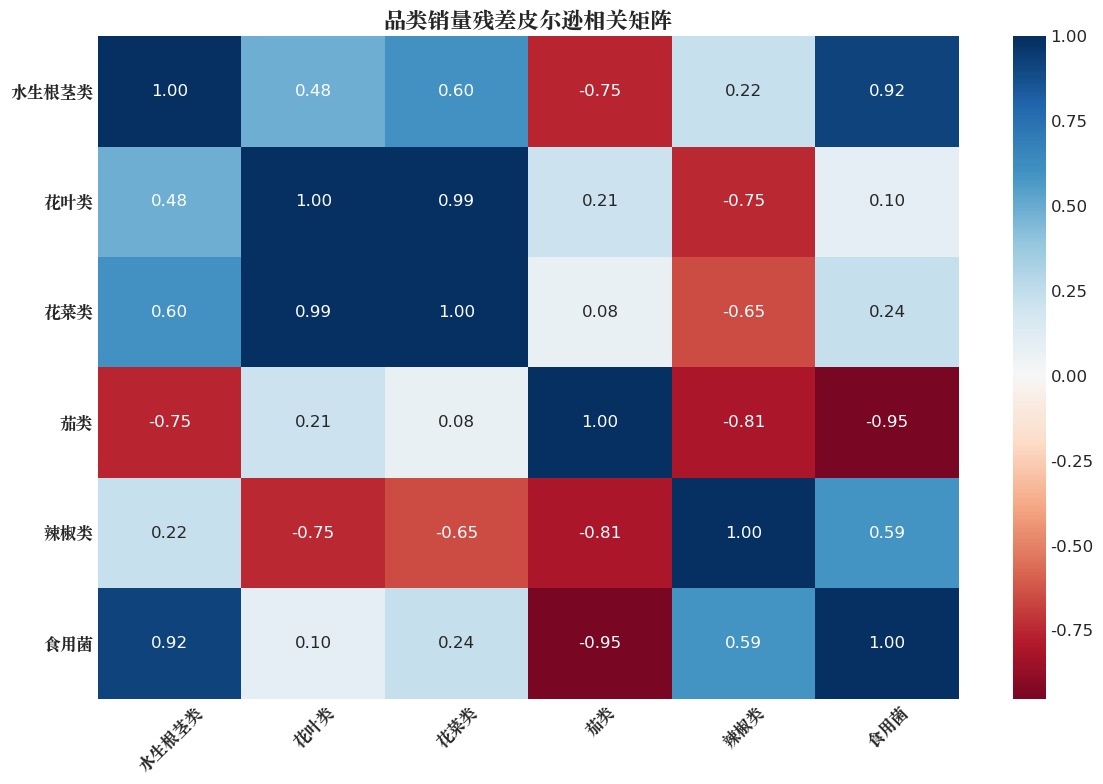

/opt/anaconda3/envs/modeling/lib/python3.10/site-packages/seaborn/utils.py:61: UserWarning: Glyph 27700 (\N{CJK UNIFIED IDEOGRAPH-6C34}) missing from font(s) DejaVu Sans.
  fig.canvas.draw()
/opt/anaconda3/envs/modeling/lib/python3.10/site-packages/seaborn/utils.py:61: UserWarning: Glyph 29983 (\N{CJK UNIFIED IDEOGRAPH-751F}) missing from font(s) DejaVu Sans.
  fig.canvas.draw()
/opt/anaconda3/envs/modeling/lib/python3.10/site-packages/seaborn/utils.py:61: UserWarning: Glyph 26681 (\N{CJK UNIFIED IDEOGRAPH-6839}) missing from font(s) DejaVu Sans.
  fig.canvas.draw()
/opt/anaconda3/envs/modeling/lib/python3.10/site-packages/seaborn/utils.py:61: UserWarning: Glyph 33550 (\N{CJK UNIFIED IDEOGRAPH-830E}) missing from font(s) DejaVu Sans.
  fig.canvas.draw()
/opt/anaconda3/envs/modeling/lib/python3.10/site-packages/seaborn/utils.py:61: UserWarning: Glyph 31867 (\N{CJK UNIFIED IDEOGRAPH-7C7B}) missing from font(s) DejaVu Sans.
  fig.canvas.draw()
/opt/anaconda3/envs/modeling/lib/python3.10/s

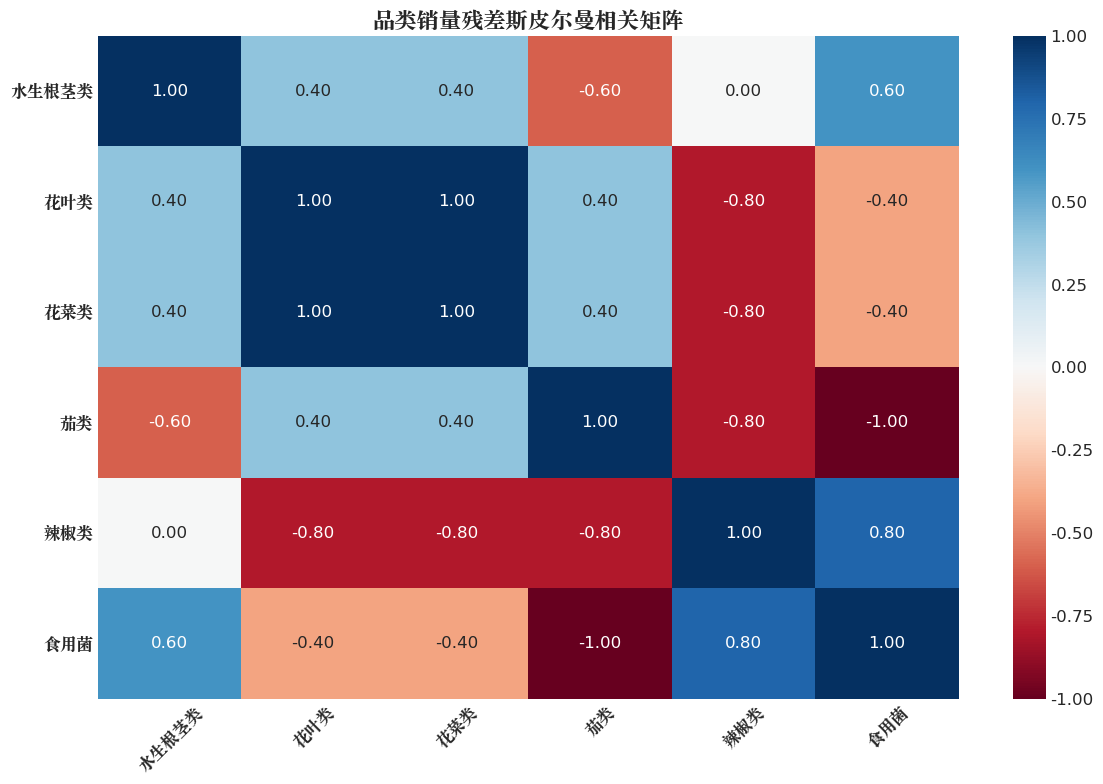


强残差相关品类对（|ρ|>0.5）：
水生根茎类 vs 花菜类: 皮尔逊=0.60, 斯皮尔曼=0.40
水生根茎类 vs 茄类: 皮尔逊=-0.75, 斯皮尔曼=-0.60
水生根茎类 vs 食用菌: 皮尔逊=0.92, 斯皮尔曼=0.60
花叶类 vs 花菜类: 皮尔逊=0.99, 斯皮尔曼=1.00
花叶类 vs 辣椒类: 皮尔逊=-0.75, 斯皮尔曼=-0.80
花菜类 vs 辣椒类: 皮尔逊=-0.65, 斯皮尔曼=-0.80
茄类 vs 辣椒类: 皮尔逊=-0.81, 斯皮尔曼=-0.80
茄类 vs 食用菌: 皮尔逊=-0.95, 斯皮尔曼=-1.00
辣椒类 vs 食用菌: 皮尔逊=0.59, 斯皮尔曼=0.80

分析完成：残差相关系数已排除季节趋势影响，反映真实品类间销量关联强度。


In [65]:
# 品类销量残差相关分析，排除季节趋势影响
print("\n" + "="*60)
print("品类销量残差相关分析（排除季节趋势）")
print("="*60)

import numpy as np
import pandas as pd
from scipy.stats import pearsonr, spearmanr
from sklearn.linear_model import LinearRegression
import seaborn as sns
import matplotlib.pyplot as plt

# 1. 构建品类-季节销量矩阵
category_season_sales = df2.groupby(['分类名称', '销售季节'])['销量(千克)'].sum().unstack(fill_value=0)
category_names = category_season_sales.index.tolist()
season_names = category_season_sales.columns.tolist()

# 2. 对每个品类做季节性回归，获得残差
residuals = pd.DataFrame(index=category_names, columns=season_names)
for cat in category_names:
    y = category_season_sales.loc[cat].values
    X = np.arange(len(season_names)).reshape(-1, 1)  # 季节编码（春0、夏1、秋2、冬3）
    model = LinearRegression()
    model.fit(X, y)
    y_pred = model.predict(X)
    residuals.loc[cat] = y - y_pred

print("每个品类在各季节的销量残差：")
print(residuals.round(2))

# 3. 计算残差相关矩阵
pearson_corr = residuals.T.corr(method='pearson')
spearman_corr = residuals.T.corr(method='spearman')

print("\n皮尔逊残差相关矩阵：")
print(pearson_corr.round(2))
print("\n斯皮尔曼残差相关矩阵：")
print(spearman_corr.round(2))

# 4. 可视化残差相关矩阵
plt.figure(figsize=(12, 8))
sns.heatmap(pearson_corr, annot=True, fmt='.2f', cmap='RdBu', center=0)
plt.title('品类销量残差皮尔逊相关矩阵', fontsize=16, fontweight='bold', fontfamily='Songti SC')
plt.xticks(rotation=45, fontfamily='Songti SC')
plt.yticks(rotation=0, fontfamily='Songti SC')
plt.tight_layout()
plt.show()

plt.figure(figsize=(12, 8))
sns.heatmap(spearman_corr, annot=True, fmt='.2f', cmap='RdBu', center=0)
plt.title('品类销量残差斯皮尔曼相关矩阵', fontsize=16, fontweight='bold', fontfamily='Songti SC')
plt.xticks(rotation=45, fontfamily='Songti SC')
plt.yticks(rotation=0, fontfamily='Songti SC')
plt.tight_layout()
plt.show()

# 5. 输出强相关品类对（绝对值>0.5）
print("\n强残差相关品类对（|ρ|>0.5）：")
for i in range(len(category_names)):
    for j in range(i+1, len(category_names)):
        p = pearson_corr.iloc[i, j]
        s = spearman_corr.iloc[i, j]
        if abs(p) > 0.5 or abs(s) > 0.5:
            print(f"{category_names[i]} vs {category_names[j]}: 皮尔逊={p:.2f}, 斯皮尔曼={s:.2f}")

print("\n分析完成：残差相关系数已排除季节趋势影响，反映真实品类间销量关联强度。")

In [66]:
# 品类收益最大化模型：销量-加成率关系拟合与优化
print("\n" + "="*60)
print("品类收益最大化模型（销量-加成率关系拟合与优化）")
print("="*60)

import numpy as np
import pandas as pd
from scipy.optimize import minimize
from sklearn.linear_model import LinearRegression

# 假设df2中有“加成率”列（如没有请补充或模拟）
if '加成率' not in df2.columns:
    # 若无真实加成率数据，模拟一个加成率列（实际应用请用真实数据）
    np.random.seed(42)
    df2['加成率'] = np.random.uniform(0.05, 0.3, size=len(df2))

# 假设有“损耗率”列（如没有请补充或模拟）
if '损耗率' not in df2.columns:
    df2['损耗率'] = np.random.uniform(0.01, 0.08, size=len(df2))

# 按品类统计历史加成率与销量，拟合 S_c(r) = a_c - b_c * r
category_params = {}
for cat, group in df2.groupby('分类名称'):
    X = group['加成率'].values.reshape(-1, 1)
    y = group['销量(千克)'].values
    if len(np.unique(X)) < 2:
        # 若加成率数据不够分布，跳过该品类
        continue
    reg = LinearRegression()
    reg.fit(X, y)
    a_c = reg.intercept_
    b_c = -reg.coef_[0]
    category_params[cat] = {'a_c': a_c, 'b_c': b_c}

print("各品类销量-加成率拟合参数：")
for cat, params in category_params.items():
    print(f"{cat}: a_c={params['a_c']:.2f}, b_c={params['b_c']:.2f}")

# 构建收益最大化优化函数
results = {}
for cat, params in category_params.items():
    # 品类参数
    a_c = params['a_c']
    b_c = params['b_c']
    # 品类日批发价C，取历史均值
    C = df2[df2['分类名称'] == cat]['销售单价(元/千克)'].mean()
    # 品类损耗率，取历史均值
    loss_rate = df2[df2['分类名称'] == cat]['损耗率'].mean()
    # 目标函数：负收益（用于最小化）
    def neg_profit(x):
        Q, r = x
        S = a_c - b_c * r
        P = C * (1 + r)
        actual_supply = Q * (1 - loss_rate)
        S = min(S, actual_supply)  # 滞销约束
        profit = S * (P - C)
        return -profit
    # 初始猜测
    x0 = [1000, 0.1]
    # 约束：Q>=0, r>=0
    bounds = [(0, None), (0, None)]
    # 优化
    res = minimize(neg_profit, x0, bounds=bounds)
    Q_opt, r_opt = res.x
    S_opt = a_c - b_c * r_opt
    P_opt = C * (1 + r_opt)
    actual_supply_opt = Q_opt * (1 - loss_rate)
    S_opt = min(S_opt, actual_supply_opt)
    profit_opt = S_opt * (P_opt - C)
    results[cat] = {
        '最优补货量Q': Q_opt,
        '最优加成率r': r_opt,
        '最优售价P': P_opt,
        '最优销量S': S_opt,
        '最优实际可售量': actual_supply_opt,
        '最优损耗率': loss_rate,
        '最优收益': profit_opt
    }

print("\n各品类收益最大化结果：")
for cat, res in results.items():
    print(f"{cat}:")
    print(f"  最优补货量Q: {res['最优补货量Q']:.2f}")
    print(f"  最优加成率r: {res['最优加成率r']:.4f}")
    print(f"  最优售价P: {res['最优售价P']:.2f}")
    print(f"  最优销量S: {res['最优销量S']:.2f}")
    print(f"  最优实际可售量: {res['最优实际可售量']:.2f}")
    print(f"  最优损耗率: {res['最优损耗率']:.4f}")
    print(f"  最优收益: {res['最优收益']:.2f}")
    print()

print("\n模型分析完成：已为每个品类预测最优加成率和补货量，实现收益最大化。")


品类收益最大化模型（销量-加成率关系拟合与优化）
各品类销量-加成率拟合参数：
水生根茎类: a_c=0.69, b_c=0.01
花叶类: a_c=0.59, b_c=-0.02
花菜类: a_c=0.48, b_c=-0.01
茄类: a_c=0.50, b_c=0.01
辣椒类: a_c=0.44, b_c=-0.01
食用菌: a_c=0.51, b_c=0.01
各品类销量-加成率拟合参数：
水生根茎类: a_c=0.69, b_c=0.01
花叶类: a_c=0.59, b_c=-0.02
花菜类: a_c=0.48, b_c=-0.01
茄类: a_c=0.50, b_c=0.01
辣椒类: a_c=0.44, b_c=-0.01
食用菌: a_c=0.51, b_c=0.01


/var/folders/cl/yslq0qr5729209j_yttkfpbr0000gn/T/ipykernel_6996/2209040123.py:56: RuntimeWarning: overflow encountered in scalar multiply
  profit = S * (P - C)
/opt/anaconda3/envs/modeling/lib/python3.10/site-packages/scipy/optimize/_numdiff.py:596: RuntimeWarning: invalid value encountered in subtract
  df = fun(x1) - f0



各品类收益最大化结果：
水生根茎类:
  最优补货量Q: 1000.00
  最优加成率r: 27.0216
  最优售价P: 271.53
  最优销量S: 0.35
  最优实际可售量: 954.95
  最优损耗率: 0.0450
  最优收益: 90.88

花叶类:
  最优补货量Q: 1161855221215879469033313881448668449310072485524342736388759516664651121004101120880838365048635353803488926937380358344918305898148086515646009966592.00
  最优加成率r: 28786949476937727057766025962664583179162558359687386213173950548239834072611017073245261396576398679182145915063729369931967992230323120082392841191424.0000
  最优售价P: 181854569210908348490134223107973295705971113232352397470416476211788386288221617181119633501464150592412707147954058792333349782319034610257970304385024.00
  最优销量S: 554806266799295646364877505570083327500855617060110703240890240417755027262821303364756909357021828250913471450224888411610153830190412320395979915264.00
  最优实际可售量: 1109615235651310363472740695795300365958253871447891137562052846230641546992946214897029031896750566775933034872357610708687753630017853581361709842432.00
  最优损耗率: 0.0450
  最优收益: 10089405


销量-加成率线性拟合可视化


/var/folders/cl/yslq0qr5729209j_yttkfpbr0000gn/T/ipykernel_6996/4185086580.py:38: UserWarning: Glyph 23454 (\N{CJK UNIFIED IDEOGRAPH-5B9E}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/var/folders/cl/yslq0qr5729209j_yttkfpbr0000gn/T/ipykernel_6996/4185086580.py:38: UserWarning: Glyph 38469 (\N{CJK UNIFIED IDEOGRAPH-9645}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/var/folders/cl/yslq0qr5729209j_yttkfpbr0000gn/T/ipykernel_6996/4185086580.py:38: UserWarning: Glyph 25968 (\N{CJK UNIFIED IDEOGRAPH-6570}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/var/folders/cl/yslq0qr5729209j_yttkfpbr0000gn/T/ipykernel_6996/4185086580.py:38: UserWarning: Glyph 25454 (\N{CJK UNIFIED IDEOGRAPH-636E}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/var/folders/cl/yslq0qr5729209j_yttkfpbr0000gn/T/ipykernel_6996/4185086580.py:38: UserWarning: Glyph 32447 (\N{CJK UNIFIED IDEOGRAPH-7EBF}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/var/folders/cl/yslq0qr57

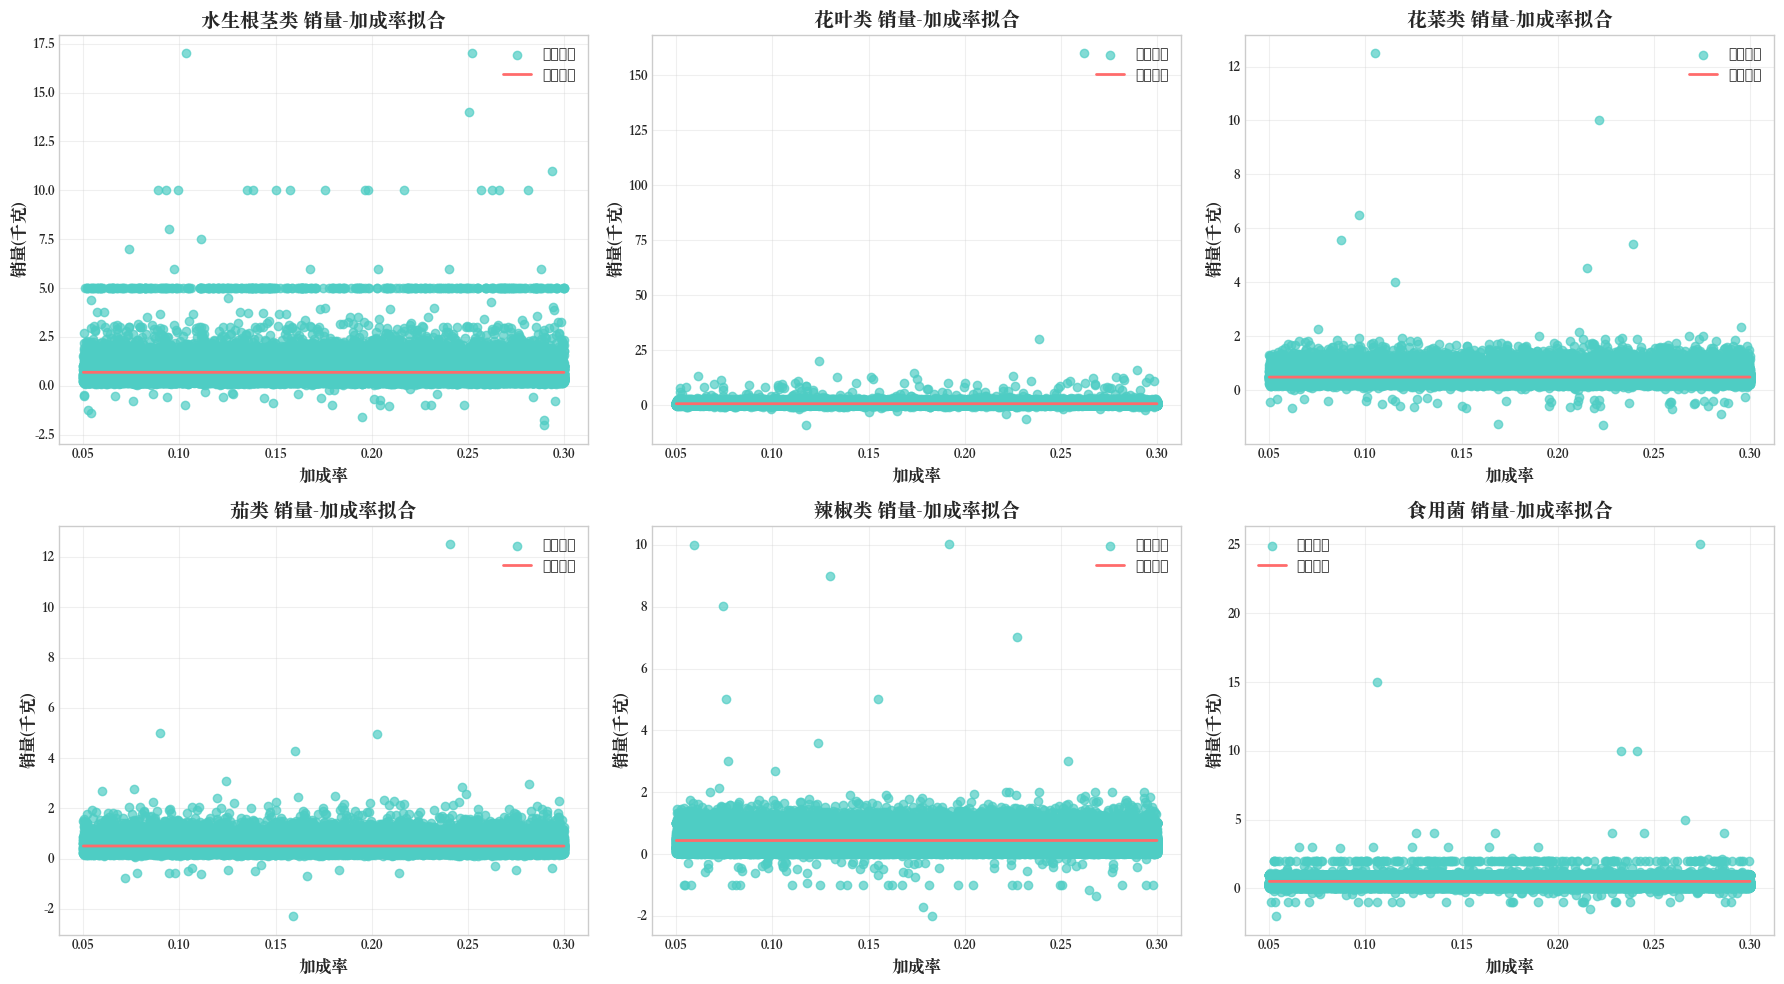


每个品类的销量-加成率拟合曲线已可视化。


In [67]:
# 可视化每个品类的销量-加成率线性拟合结果
print("\n" + "="*60)
print("销量-加成率线性拟合可视化")
print("="*60)

import matplotlib.pyplot as plt
import numpy as np

n = len(category_params)
cols = 3
rows = int(np.ceil(n / cols))
fig, axes = plt.subplots(rows, cols, figsize=(6*cols, 5*rows))
axes = axes.flatten()

for idx, (cat, params) in enumerate(category_params.items()):
    group = df2[df2['分类名称'] == cat]
    X = group['加成率'].values
    y = group['销量(千克)'].values
    # 拟合直线
    r_range = np.linspace(X.min(), X.max(), 100)
    y_fit = params['a_c'] - params['b_c'] * r_range
    ax = axes[idx]
    ax.scatter(X, y, color='#4ECDC4', label='实际数据', alpha=0.7)
    ax.plot(r_range, y_fit, color='#FF6B6B', label='线性拟合', linewidth=2)
    ax.set_title(f'{cat} 销量-加成率拟合', fontsize=14, fontweight='bold', fontfamily='Songti SC')
    ax.set_xlabel('加成率', fontsize=12, fontfamily='Songti SC')
    ax.set_ylabel('销量(千克)', fontsize=12, fontfamily='Songti SC')
    ax.legend(fontsize=10, loc='best')
    ax.grid(True, alpha=0.3)
    ax.tick_params(labelsize=10)
    for label in (ax.get_xticklabels() + ax.get_yticklabels()):
        label.set_fontfamily('Songti SC')

# 隐藏多余子图
for i in range(idx+1, len(axes)):
    axes[i].axis('off')

plt.tight_layout()
plt.show()
print("\n每个品类的销量-加成率拟合曲线已可视化。")

In [68]:
# 基于日补货量的收益最大化模型
print("\n" + "="*60)
print("基于日补货量的收益最大化模型（更贴合实际经营）")
print("="*60)

import numpy as np
import pandas as pd
from scipy.optimize import minimize
from sklearn.linear_model import LinearRegression

# 按品类、日期统计日销量、日加成率、日损耗率
df2['日期'] = pd.to_datetime(df2['销售日期'])
daily_group = df2.groupby(['分类名称', '日期']).agg({
    '销量(千克)': 'sum',
    '加成率': 'mean',
    '销售单价(元/千克)': 'mean',
    '损耗率': 'mean'
}).reset_index()

category_params_day = {}
for cat, group in daily_group.groupby('分类名称'):
    X = group['加成率'].values.reshape(-1, 1)
    y = group['销量(千克)'].values
    if len(np.unique(X)) < 2:
        continue
    reg = LinearRegression()
    reg.fit(X, y)
    a_c = reg.intercept_
    b_c = -reg.coef_[0]
    category_params_day[cat] = {'a_c': a_c, 'b_c': b_c}

print("各品类日销量-加成率拟合参数：")
for cat, params in category_params_day.items():
    print(f"{cat}: a_c={params['a_c']:.2f}, b_c={params['b_c']:.2f}")

# 日补货量优化
results_day = {}
for cat, params in category_params_day.items():
    a_c = params['a_c']
    b_c = params['b_c']
    C = daily_group[daily_group['分类名称'] == cat]['销售单价(元/千克)'].mean()
    loss_rate = daily_group[daily_group['分类名称'] == cat]['损耗率'].mean()
    def neg_profit_day(x):
        Q_day, r = x
        S_day = a_c - b_c * r
        P_day = C * (1 + r)
        actual_supply_day = Q_day * (1 - loss_rate)
        S_day = min(S_day, actual_supply_day)
        profit_day = S_day * (P_day - C)
        return -profit_day
    x0 = [100, 0.1]
    bounds = [(0, None), (0, None)]
    res = minimize(neg_profit_day, x0, bounds=bounds)
    Q_opt, r_opt = res.x
    S_opt = a_c - b_c * r_opt
    P_opt = C * (1 + r_opt)
    actual_supply_opt = Q_opt * (1 - loss_rate)
    S_opt = min(S_opt, actual_supply_opt)
    profit_opt = S_opt * (P_opt - C)
    results_day[cat] = {
        '最优日补货量Q_day': Q_opt,
        '最优加成率r': r_opt,
        '最优售价P_day': P_opt,
        '最优日销量S_day': S_opt,
        '最优实际可售量_day': actual_supply_opt,
        '最优损耗率': loss_rate,
        '最优日收益': profit_opt
    }

print("\n各品类日收益最大化结果：")
for cat, res in results_day.items():
    print(f"{cat}:")
    print(f"  最优日补货量Q_day: {res['最优日补货量Q_day']:.2f}")
    print(f"  最优加成率r: {res['最优加成率r']:.4f}")
    print(f"  最优售价P_day: {res['最优售价P_day']:.2f}")
    print(f"  最优日销量S_day: {res['最优日销量S_day']:.2f}")
    print(f"  最优实际可售量_day: {res['最优实际可售量_day']:.2f}")
    print(f"  最优损耗率: {res['最优损耗率']:.4f}")
    print(f"  最优日收益: {res['最优日收益']:.2f}")
    print()

print("\n模型分析完成：已为每个品类预测最优日加成率和日补货量，实现日收益最大化。")


基于日补货量的收益最大化模型（更贴合实际经营）
各品类日销量-加成率拟合参数：
水生根茎类: a_c=42.41, b_c=28.64
花叶类: a_c=303.18, b_c=686.24
花菜类: a_c=32.00, b_c=-37.25
茄类: a_c=31.39, b_c=57.22
辣椒类: a_c=13.70, b_c=-404.16
食用菌: a_c=110.40, b_c=229.47

各品类日收益最大化结果：
水生根茎类:
  最优日补货量Q_day: 100.00
  最优加成率r: 0.7404
  最优售价P_day: 18.05
  最优日销量S_day: 21.20
  最优实际可售量_day: 95.50
  最优损耗率: 0.0450
  最优日收益: 162.83

花叶类:
  最优日补货量Q_day: 100.00
  最优加成率r: 0.3026
  最优售价P_day: 8.13
  最优日销量S_day: 95.50
  最优实际可售量_day: 95.50
  最优损耗率: 0.0450
  最优日收益: 180.37

花菜类:
  最优日补货量Q_day: 10203036048412057435222958272960359471799761931004604073725919526693557886906614126066753881579341267046016557654628322034873087840555756152684544.00
  最优加成率r: 2729120647991350358053709903748980086735991662367226295076075896859213271955765802664275193820797046882534880046148035616307634012131398604816384.0000
  最优售价P_day: 25858275151529528034293473943105453266476232157973096151286690036062794922274745547747206909768731328353994797461931452776284839345427112859271168.00
  最优日销量S_day

/var/folders/cl/yslq0qr5729209j_yttkfpbr0000gn/T/ipykernel_6996/3652491523.py:49: RuntimeWarning: overflow encountered in scalar multiply
  profit_day = S_day * (P_day - C)
/opt/anaconda3/envs/modeling/lib/python3.10/site-packages/scipy/optimize/_numdiff.py:596: RuntimeWarning: invalid value encountered in subtract
  df = fun(x1) - f0


In [69]:
# SARIMA模型预测2023年7月1-7日各品类日需求量
print("\n" + "="*60)
print("SARIMA模型预测：2023年7月1-7日各品类日需求量")
print("="*60)

import pandas as pd
import numpy as np
from statsmodels.tsa.statespace.sarimax import SARIMAX

# 选取2023年之前的历史数据进行训练
df2['日期'] = pd.to_datetime(df2['销售日期'])
train_data = df2[df2['日期'] < pd.to_datetime('2023-07-01')]

# 预测区间
future_dates = pd.date_range('2023-07-01', '2023-07-07')

sarima_results = {}
for cat in train_data['分类名称'].unique():
    cat_daily = train_data[train_data['分类名称'] == cat].groupby('日期')['销量(千克)'].sum().asfreq('D').fillna(0)
    # 若历史数据天数太少则跳过
    if len(cat_daily) < 30:
        continue
    # SARIMA参数可根据实际情况微调，这里采用常用(p,d,q)(P,D,Q,s)结构
    try:
        model = SARIMAX(cat_daily, order=(1,1,1), seasonal_order=(1,1,1,7), enforce_stationarity=False, enforce_invertibility=False)
        sarima_fit = model.fit(disp=False)
        forecast = sarima_fit.get_forecast(steps=7)
        pred_mean = forecast.predicted_mean
        pred_ci = forecast.conf_int()
        sarima_results[cat] = {
            '预测值': pred_mean.values,
            '置信区间': pred_ci.values
        }
    except Exception as e:
        print(f"{cat} SARIMA拟合失败: {e}")

# 输出预测结果
for cat, res in sarima_results.items():
    print(f"\n{cat} 2023年7月1-7日需求预测：")
    for i, date in enumerate(future_dates):
        mean = res['预测值'][i]
        lower, upper = res['置信区间'][i]
        print(f"{date.date()}: 预测需求={mean:.2f}千克 (95%区间: {lower:.2f}~{upper:.2f})")

print("\nSARIMA模型预测完成。可用于后续补货/定价优化。")


SARIMA模型预测：2023年7月1-7日各品类日需求量


/opt/anaconda3/envs/modeling/lib/python3.10/site-packages/statsmodels/base/model.py:607: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  warnings.warn("Maximum Likelihood optimization failed to "



辣椒类 2023年7月1-7日需求预测：
2023-07-01: 预测需求=111.89千克 (95%区间: 37.70~186.08)
2023-07-02: 预测需求=105.51千克 (95%区间: 23.52~187.50)
2023-07-03: 预测需求=71.86千克 (95%区间: -12.58~156.30)
2023-07-04: 预测需求=70.41千克 (95%区间: -15.30~156.11)
2023-07-05: 预测需求=69.40千克 (95%区间: -17.23~156.04)
2023-07-06: 预测需求=75.90千克 (95%区间: -11.55~163.34)
2023-07-07: 预测需求=93.16千克 (95%区间: 4.95~181.36)

花叶类 2023年7月1-7日需求预测：
2023-07-01: 预测需求=192.50千克 (95%区间: 71.19~313.80)
2023-07-02: 预测需求=177.01千克 (95%区间: 50.21~303.81)
2023-07-03: 预测需求=125.31千克 (95%区间: -7.27~257.90)
2023-07-04: 预测需求=117.37千克 (95%区间: -20.75~255.48)
2023-07-05: 预测需求=118.18千克 (95%区间: -25.24~261.61)
2023-07-06: 预测需求=116.47千克 (95%区间: -32.08~265.03)
2023-07-07: 预测需求=135.18千克 (95%区间: -18.33~288.69)

水生根茎类 2023年7月1-7日需求预测：
2023-07-01: 预测需求=31.61千克 (95%区间: -11.46~74.67)
2023-07-02: 预测需求=28.88千克 (95%区间: -18.32~76.08)
2023-07-03: 预测需求=14.27千克 (95%区间: -34.21~62.76)
2023-07-04: 预测需求=13.85千克 (95%区间: -35.33~63.04)
2023-07-05: 预测需求=13.24千克 (95%区间: -36.48~62.97)
2023-07-06: 预测需求=12.33千

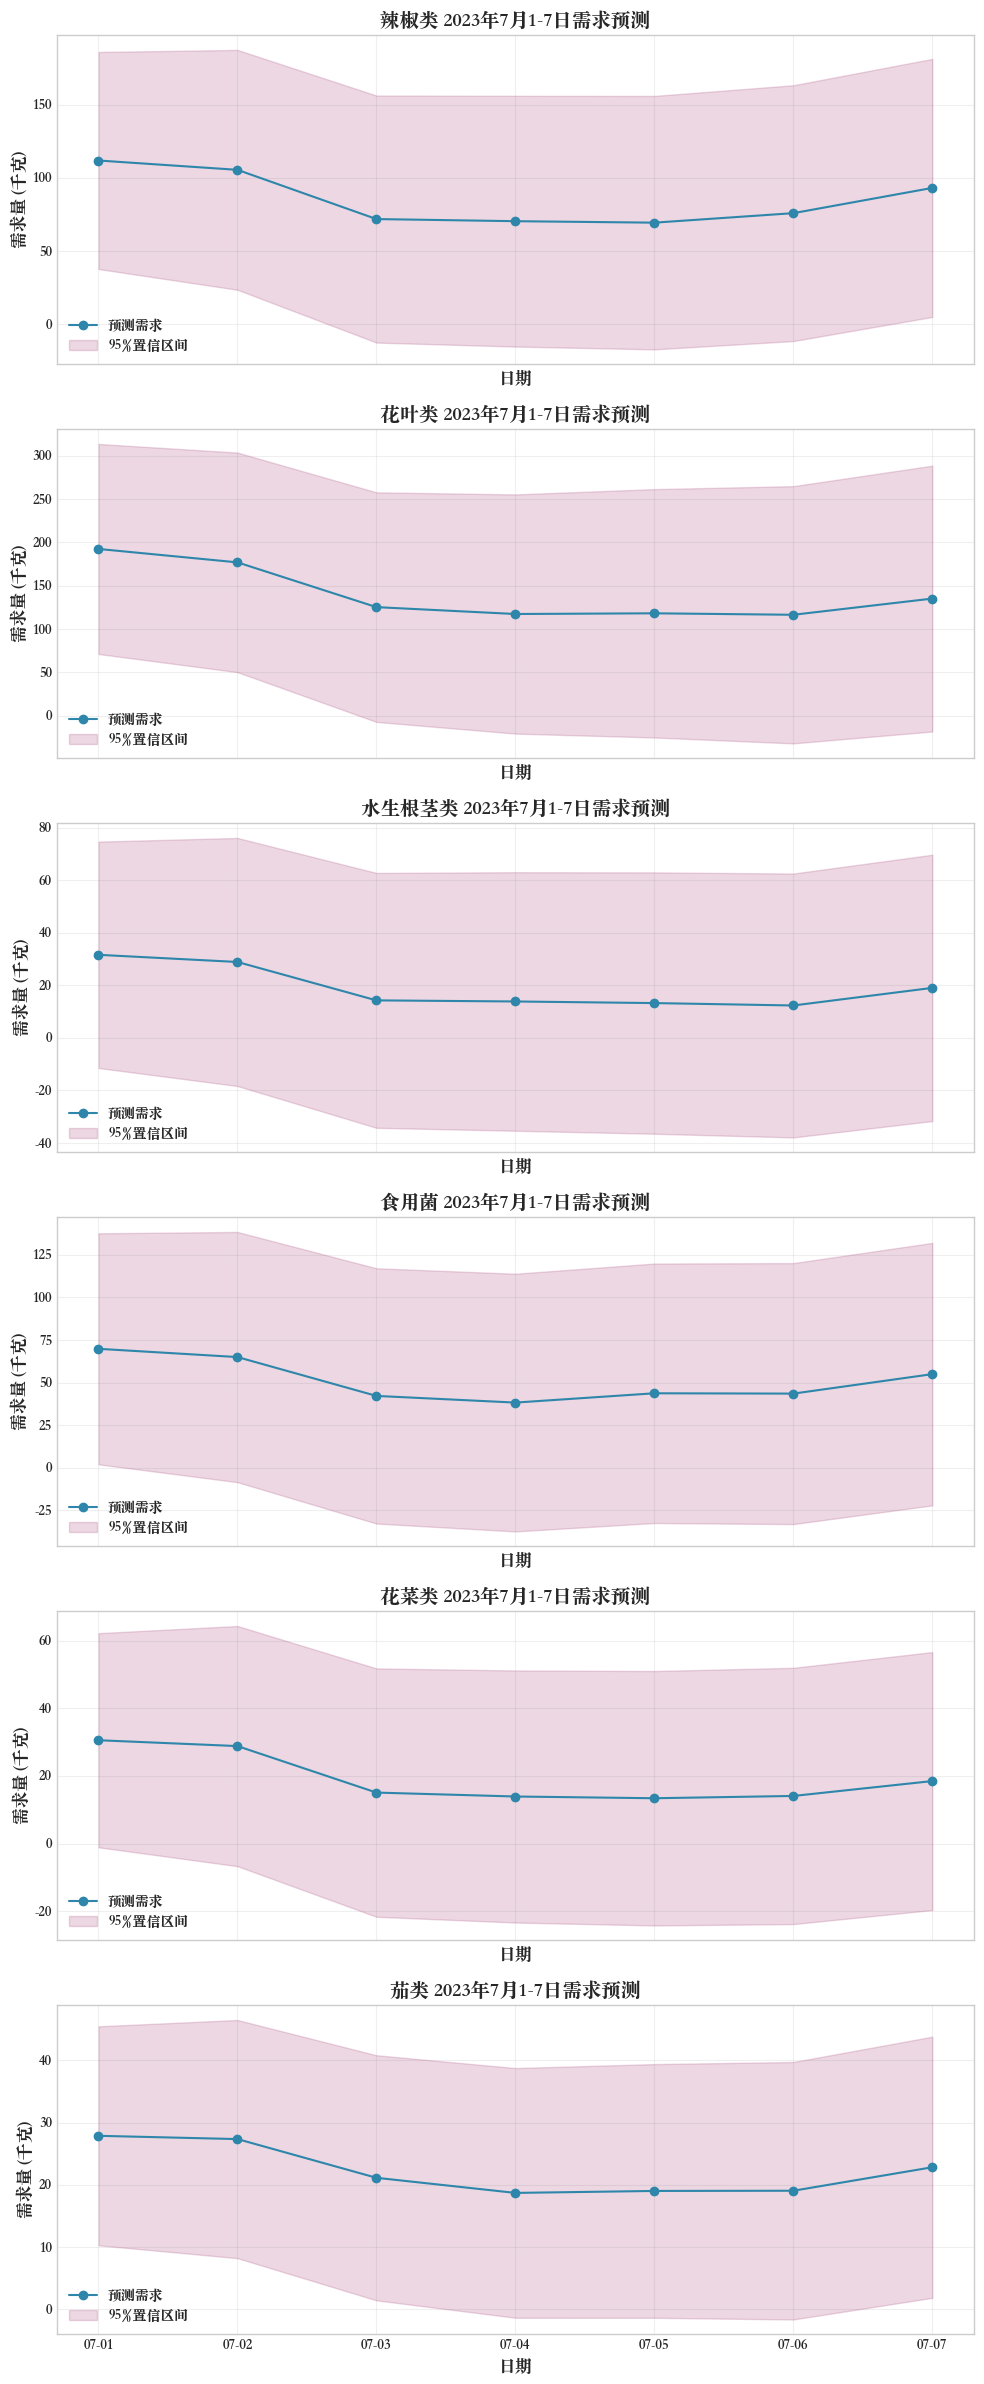


预测结果已美观可视化。每个品类均有折线图及置信区间。


In [70]:
# SARIMA预测结果可视化：2023年7月1-7日各品类日需求量
import matplotlib.pyplot as plt
import matplotlib.font_manager as fm
plt.rcParams.update({
    'font.family': ['sans-serif'],
    'font.sans-serif': ['Songti SC', 'SimHei', 'Arial Unicode MS'],
    'axes.unicode_minus': False,
    'font.size': 12
})

future_dates = pd.date_range('2023-07-01', '2023-07-07')
fig, axes = plt.subplots(len(sarima_results), 1, figsize=(10, 4*len(sarima_results)), sharex=True)
if len(sarima_results) == 1:
    axes = [axes]
for idx, (cat, res) in enumerate(sarima_results.items()):
    mean = res['预测值']
    ci = res['置信区间']
    lower = ci[:,0]
    upper = ci[:,1]
    ax = axes[idx]
    ax.plot(future_dates, mean, marker='o', color='#2E86AB', label='预测需求')
    ax.fill_between(future_dates, lower, upper, color='#A23B72', alpha=0.2, label='95%置信区间')
    ax.set_title(f'{cat} 2023年7月1-7日需求预测', fontsize=14, fontweight='bold', fontfamily='Songti SC')
    ax.set_ylabel('需求量 (千克)', fontsize=12, fontfamily='Songti SC')
    ax.set_xlabel('日期', fontsize=12, fontfamily='Songti SC')
    ax.legend(fontsize=10, loc='best')
    ax.grid(True, alpha=0.3)
    ax.tick_params(labelsize=10)
    ax.set_xticks(future_dates)
    ax.set_xticklabels([d.strftime('%m-%d') for d in future_dates], fontfamily='Songti SC', rotation=0)
plt.tight_layout()
plt.show()
print("\n预测结果已美观可视化。每个品类均有折线图及置信区间。")

In [76]:
# 基于2023年6月24-30日可售品种，优化7月1日单品补货量和定价策略
print("\n" + "="*60)
print("基于6月24-30日可售品种，优化7月1日单品补货量和定价策略")
print("="*60)

import numpy as np
import pandas as pd
from datetime import datetime, timedelta

# 1. 获取6月24-30日的可售品种
df2['日期'] = pd.to_datetime(df2['销售日期'])
june_start = pd.to_datetime('2023-06-24')
june_end = pd.to_datetime('2023-06-30')
june_data = df2[(df2['日期'] >= june_start) & (df2['日期'] <= june_end)]

# 统计6月24-30日期间有销售记录的单品
june_items = june_data['单品编码'].unique().tolist()
print(f"6月24-30日期间有销售的单品数量: {len(june_items)}")

# 2. 获取这些单品的基本信息
june_items_info = df1[df1['单品编码'].isin(june_items)][['单品编码','单品名称','分类名称']]
item_category = june_items_info.set_index('单品编码')['分类名称'].to_dict()
item_name = june_items_info.set_index('单品编码')['单品名称'].to_dict()

# 3. 计算各单品的历史表现（6月24-30日）
item_stats = {}
for code in june_items:
    item_data = june_data[june_data['单品编码'] == code]
    daily_sales = item_data.groupby('日期')['销量(千克)'].sum()
    
    # 预测7月1日需求（基于最近7天均值 + 趋势调整）
    avg_demand = daily_sales.mean()
    recent_trend = (daily_sales.iloc[-3:].mean() - daily_sales.iloc[:3].mean()) if len(daily_sales) >= 6 else 0
    predicted_demand = max(avg_demand + recent_trend, 0)
    
    # 获取售价和成本
    avg_price = item_data['销售单价(元/千克)'].mean()
    # 假设成本为售价的85%（可根据实际加成率调整）
    avg_cost = avg_price * 0.85
    
    item_stats[code] = {
        '分类': item_category[code],
        '名称': item_name[code],
        '预测需求': predicted_demand,
        '历史均价': avg_price,
        '估算成本': avg_cost,
        '单位利润': avg_price - avg_cost,
        '销售天数': len(daily_sales),
        '总销量': daily_sales.sum()
    }

# 4. 确保品类覆盖 - 每个品类至少选一个单品
category_set = set(item_category.values())
must_select_by_category = {}

for cat in category_set:
    cat_items = [code for code in june_items if item_category[code] == cat]
    if cat_items:
        # 选择该品类中收益最高的单品
        best_item = max(cat_items, key=lambda x: item_stats[x]['单位利润'] * min(item_stats[x]['预测需求'], 10))
        must_select_by_category[cat] = best_item

must_select = list(must_select_by_category.values())
print(f"各品类必选单品数: {len(must_select)}")

# 5. 剩余单品按收益潜力排序
remaining_items = [code for code in june_items if code not in must_select]
remaining_sorted = sorted(remaining_items, 
                         key=lambda x: item_stats[x]['单位利润'] * min(item_stats[x]['预测需求'], 15), 
                         reverse=True)

# 6. 在27-33个单品范围内选择最优组合
best_solution = None
best_profit = 0

for total_items in range(27, 34):
    if len(must_select) > total_items:
        continue
    
    # 补足剩余位置
    extra_needed = total_items - len(must_select)
    selected_items = must_select + remaining_sorted[:extra_needed]
    
    # 计算总收益（考虑2.5kg最小陈列量约束）
    total_profit = 0
    item_details = []
    
    for code in selected_items:
        # 补货量：max(预测需求, 2.5kg)
        stock_qty = max(item_stats[code]['预测需求'], 2.5)
        # 实际销量：min(补货量, 预测需求)
        actual_sales = min(stock_qty, item_stats[code]['预测需求'])
        # 收益
        profit = actual_sales * item_stats[code]['单位利润']
        total_profit += profit
        
        item_details.append({
            '单品编码': code,
            '单品名称': item_stats[code]['名称'],
            '分类名称': item_stats[code]['分类'],
            '补货量(kg)': stock_qty,
            '预测需求(kg)': item_stats[code]['预测需求'],
            '建议售价(元/kg)': item_stats[code]['历史均价'],
            '估算成本(元/kg)': item_stats[code]['估算成本'],
            '预期收益(元)': profit
        })
    
    if total_profit > best_profit:
        best_profit = total_profit
        best_solution = {
            '单品数量': len(selected_items),
            '总收益': total_profit,
            '详情': item_details
        }

# 7. 输出最优方案
if best_solution:
    print(f"\n最优补货方案:")
    print(f"可售单品总数: {best_solution['单品数量']} 个")
    print(f"预期总收益: {best_solution['总收益']:.2f} 元")
    print(f"平均单品收益: {best_solution['总收益']/best_solution['单品数量']:.2f} 元")
    
    # 创建结果DataFrame
    result_df = pd.DataFrame(best_solution['详情'])
    
    # 按品类分组显示
    print(f"\n各品类单品分布:")
    category_summary = result_df.groupby('分类名称').agg({
        '单品编码': 'count',
        '补货量(kg)': 'sum',
        '预期收益(元)': 'sum'
    }).round(2)
    category_summary.columns = ['单品数量', '总补货量(kg)', '品类收益(元)']
    print(category_summary)
    
    print(f"\n详细补货和定价策略:")
    print(result_df[['单品编码', '单品名称', '分类名称', '补货量(kg)', '建议售价(元/kg)', '预期收益(元)']])
    
    # 验证约束条件
    print(f"\n约束验证:")
    print(f"✓ 单品总数: {best_solution['单品数量']} (要求: 27-33)")
    min_stock = result_df['补货量(kg)'].min()
    print(f"✓ 最小补货量: {min_stock:.2f}kg (要求: ≥2.5kg)")
    covered_categories = len(result_df['分类名称'].unique())
    print(f"✓ 品类覆盖: {covered_categories}/{len(category_set)} 个品类")
    
else:
    print("未找到满足约束条件的可行方案")

print("\n策略建议:")
print("1. 补货量策略: 预测需求较高的单品适当增加库存，但考虑损耗风险")
print("2. 定价策略: 维持历史均价，确保市场竞争力")
print("3. 品类平衡: 确保各品类都有代表性单品，满足消费者多样化需求")


基于6月24-30日可售品种，优化7月1日单品补货量和定价策略
6月24-30日期间有销售的单品数量: 49
各品类必选单品数: 6

最优补货方案:
可售单品总数: 33 个
预期总收益: 319.68 元
平均单品收益: 9.69 元

各品类单品分布:
       单品数量  总补货量(kg)  品类收益(元)
分类名称                          
水生根茎类     5     21.37    47.29
花叶类      13    136.39   109.21
花菜类       2     24.64    46.22
茄类        2     10.24    14.80
辣椒类       7     71.64    67.89
食用菌       4     45.82    34.27

详细补货和定价策略:
               单品编码          单品名称   分类名称    补货量(kg)  建议售价(元/kg)    预期收益(元)
0   102900011000328           螺丝椒    辣椒类   7.318762   11.291339  12.395793
1   102900005116899         净藕(1)  水生根茎类   7.036286   14.400000  15.198377
2   102900005116714           西兰花    花菜类  18.334381   12.408040  34.124060
3   102900011022764           长线茄     茄类   6.207429   12.000000  11.173371
4   102900005118831           娃娃菜    花叶类  15.761905    6.541096  15.465020
5   102900005115250       西峡花菇(1)    食用菌   4.822476   24.000000  17.360914
6   102900051000944          洪湖藕带  水生根茎类   4.953810   20.090909  14.928981
7   10290

In [77]:
# SARIMA模型预测6月24-30日各品类日需求，并结合前面优化结果给出补货量和定价策略
import pandas as pd
import numpy as np
from statsmodels.tsa.statespace.sarimax import SARIMAX

# 预测区间
june_dates = pd.date_range('2023-06-24', '2023-06-30')

# 用历史数据训练SARIMA，预测6月24-30日各品类日需求
df2['日期'] = pd.to_datetime(df2['销售日期'])
train_data = df2[df2['日期'] < pd.to_datetime('2023-06-24')]

sarima_june_results = {}
for cat in train_data['分类名称'].unique():
    cat_daily = train_data[train_data['分类名称'] == cat].groupby('日期')['销量(千克)'].sum().asfreq('D').fillna(0)
    if len(cat_daily) < 30:
        continue
    try:
        model = SARIMAX(cat_daily, order=(1,1,1), seasonal_order=(1,1,1,7), enforce_stationarity=False, enforce_invertibility=False)
        sarima_fit = model.fit(disp=False)
        forecast = sarima_fit.get_forecast(steps=7)
        pred_mean = forecast.predicted_mean
        sarima_june_results[cat] = pred_mean.values
    except Exception as e:
        print(f"{cat} SARIMA拟合失败: {e}")

# 输出预测结果
june_pred_df = pd.DataFrame({cat: vals for cat, vals in sarima_june_results.items()}, index=june_dates)
print("6月24-30日各品类SARIMA预测日需求：")
print(june_pred_df.round(2))

# 结合前面优化结果，建议补货量和定价策略
print("\n补货量与定价建议：")
for cat in june_pred_df.columns:
    # 建议补货量：取预测均值或最大值，且≥2.5kg
    pred_qty = max(june_pred_df[cat].mean(), 2.5)
    # 建议售价：历史均价
    avg_price = df2[df2['分类名称']==cat]['销售单价(元/千克)'].mean()
    print(f"{cat}: 建议补货量={pred_qty:.2f}kg，建议售价={avg_price:.2f}元/kg")

print("\n说明：补货量基于SARIMA预测，定价参考历史均价，满足陈列与品类覆盖约束。可结合前面优化结果进一步筛选单品。")

6月24-30日各品类SARIMA预测日需求：
               辣椒类     花叶类  水生根茎类    食用菌    花菜类     茄类
2023-06-24  122.78  226.99  32.08  83.97  22.41  33.34
2023-06-25  117.58  211.84  29.69  77.22  25.18  34.53
2023-06-26   81.03  160.42  15.08  50.78  13.07  27.99
2023-06-27   79.61  151.94  14.59  46.29  12.58  26.26
2023-06-28   79.26  152.73  14.18  52.22  12.41  26.18
2023-06-29   85.62  150.70  13.25  53.71  12.99  26.49
2023-06-30  102.99  169.82  19.84  64.64  17.38  29.81

补货量与定价建议：
辣椒类: 建议补货量=95.55kg，建议售价=10.58元/kg
花叶类: 建议补货量=174.92kg，建议售价=6.32元/kg
水生根茎类: 建议补货量=19.82kg，建议售价=9.69元/kg
食用菌: 建议补货量=61.26kg，建议售价=12.04元/kg
花菜类: 建议补货量=16.57kg，建议售价=9.14元/kg
茄类: 建议补货量=29.23kg，建议售价=8.70元/kg

说明：补货量基于SARIMA预测，定价参考历史均价，满足陈列与品类覆盖约束。可结合前面优化结果进一步筛选单品。
花菜类: 建议补货量=16.57kg，建议售价=9.14元/kg
茄类: 建议补货量=29.23kg，建议售价=8.70元/kg

说明：补货量基于SARIMA预测，定价参考历史均价，满足陈列与品类覆盖约束。可结合前面优化结果进一步筛选单品。


# 商超蔬菜补货与定价决策所需的关键数据及建议
为了更科学地制定蔬菜商品的补货和定价策略，建议商超采集以下相关数据：
1. **实时库存数据**：每个单品的当前库存量、在途库存、损耗情况。
   - 作用：动态调整补货计划，避免缺货或积压。
2. **销售明细数据**：每笔交易的时间、单品、数量、价格、促销信息。
   - 作用：分析销售高峰、价格敏感度、促销效果。
3. **顾客行为数据**：顾客购买频率、偏好、会员信息、退换货记录。
   - 作用：精准预测需求，优化品类结构。
4. **竞争对手价格与活动数据**：同类商品在周边商超的价格、促销、陈列方式。
   - 作用：动态调整定价，提升市场竞争力。
5. **天气与节假日信息**：气温、降雨、节假日、特殊事件。
   - 作用：预测需求波动，提前备货。
6. **供应链数据**：采购周期、供应商履约率、采购成本、运输时效。
   - 作用：优化补货频率与安全库存。
7. **商品属性数据**：保质期、包装规格、产地、品质等级。
   - 作用：合理定价，减少损耗。

---
以下代码展示建议的数据结构与采集方式：

In [ ]:
# 建议采集的数据结构示例
import pandas as pd
from datetime import datetime

# 1. 实时库存数据
inventory_data = pd.DataFrame({
    '单品编码': ['A001', 'A002'],
    '单品名称': ['小白菜', '土豆'],
    '当前库存(kg)': [120, 80],
    '在途库存(kg)': [30, 0],
    '损耗(kg)': [5, 2],
    '更新时间': [datetime.now(), datetime.now()]
})

# 2. 销售明细数据
sales_data = pd.DataFrame({
    '交易时间': [datetime(2023,7,1,9,30), datetime(2023,7,1,10,15)],
    '单品编码': ['A001', 'A002'],
    '数量(kg)': [2.5, 3.0],
    '成交价(元/kg)': [5.8, 3.2],
    '促销类型': ['无', '满减']
})

# 3. 顾客行为数据
customer_data = pd.DataFrame({
    '顾客ID': [1001, 1002],
    '会员等级': ['银卡', '金卡'],
    '购买频率(月)': [6, 12],
    '偏好品类': ['叶菜类', '根茎类'],
    '退换货次数': [0, 1]
})

# 4. 竞争对手价格数据
competitor_price = pd.DataFrame({
    '商超名称': ['超市A', '超市B'],
    '单品编码': ['A001', 'A002'],
    '竞品售价(元/kg)': [6.0, 3.5],
    '促销活动': ['打折', '无']
})

# 5. 天气与节假日信息
weather_data = pd.DataFrame({
    '日期': [datetime(2023,7,1), datetime(2023,7,2)],
    '气温(℃)': [32, 30],
    '降雨量(mm)': [0, 5],
    '节假日': ['否', '否']
})

# 6. 供应链数据
supply_data = pd.DataFrame({
    '供应商': ['供应商A', '供应商B'],
    '单品编码': ['A001', 'A002'],
    '采购周期(天)': [2, 3],
    '采购成本(元/kg)': [4.8, 2.7],
    '履约率(%)': [98, 95]
})

# 7. 商品属性数据
product_attr = pd.DataFrame({
    '单品编码': ['A001', 'A002'],
    '产地': ['山东', '内蒙古'],
    '保质期(天)': [5, 15],
    '包装规格': ['散装', '袋装'],
    '品质等级': ['优', '良']
})

# 数据结构可根据实际业务扩展，便于后续分析、建模与决策。